# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
import kagglehub
import pandas as pd
import os

# Baixa a versão mais recente
path = kagglehub.dataset_download(
    "jessemostipak/hotel-booking-demand"
)

# Dados de reservas dos hotéis
arquivo_csv = os.path.join(path, "hotel_bookings.csv")

df = pd.read_csv(arquivo_csv)

print("Arquivo importado:", arquivo_csv)
df.head()

C:\Users\ASUS\OneDrive\Documentos\django\AVD-20262-pratica-streamlit\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0.00/1.25M [00:00<?, ?B/s]

 80%|████████  | 1.00M/1.25M [00:00<00:00, 1.17MB/s]

100%|██████████| 1.25M/1.25M [00:00<00:00, 1.34MB/s]

Extracting files...


Arquivo importado: C:\Users\ASUS\.cache\kagglehub\datasets\jessemostipak\hotel-booking-demand\versions\1\hotel_bookings.csv


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

### Dimensão e Tipos de Dados

In [3]:
df.shape

(119390, 32)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [5]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


### Duplicadas

In [6]:
df.duplicated().sum()
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo-alvo para facilitar a interpretação

O dataset original registra is_canceled como 0 para reservas não canceladas e 1 para reservas canceladas. Para facilitar a interpretação dos gráficos, vamos substituir esses valores por categorias textuais.

In [7]:
df["status_reserva"] = df["is_canceled"].map({
    0: "Não cancelada",
    1: "Cancelada"
})

df["status_reserva"].value_counts()

df.drop(columns=["is_canceled"], inplace=True)

df.head()

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,status_reserva
0,Resort Hotel,342,2015,July,27,1,0,0,2,0.0,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,Não cancelada
1,Resort Hotel,737,2015,July,27,1,0,0,2,0.0,...,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,Não cancelada
2,Resort Hotel,7,2015,July,27,1,0,1,1,0.0,...,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,Não cancelada
3,Resort Hotel,13,2015,July,27,1,0,1,1,0.0,...,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,Não cancelada
4,Resort Hotel,14,2015,July,27,1,0,2,2,0.0,...,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,Não cancelada


## 2. Dados Faltantes

In [8]:
df.isna().sum()

hotel                                 0
lead_time                             0
arrival_date_year                     0
arrival_date_month                    0
arrival_date_week_number              0
arrival_date_day_of_month             0
stays_in_weekend_nights               0
stays_in_week_nights                  0
adults                                0
children                              4
babies                                0
meal                                  0
country                             452
market_segment                        0
distribution_channel                  0
is_repeated_guest                     0
previous_cancellations                0
previous_bookings_not_canceled        0
reserved_room_type                    0
assigned_room_type                    0
booking_changes                       0
deposit_type                          0
agent                             12193
company                           82137
days_in_waiting_list                  0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim. O dataset apresenta valores ausentes em quatro variáveis:

- `children`: 4 valores ausentes;
- `country`: 488 valores ausentes;
- `agent`: 16.340 valores ausentes;
- `company`: 112.593 valores ausentes.

A variável `company` possui a maior ausência, com aproximadamente 94% dos registros, enquanto `children` e `country` têm poucos dados faltantes. Portanto, cada variável deverá receber um tratamento adequado conforme sua natureza e proporção de ausência.

#### Identificando o mecanismo de dados ausentes

# Conhecimento de Domínio

O comando `df.isna().sum()` identificou valores ausentes nas colunas `children`, `country`, `agent` e `company`.

Pela fonte dos dados, observamos que:

- `hotel` — tipo de hotel;
- `lead_time` — dias entre a reserva e a chegada;
- `adults`, `children` e `babies` — quantidade de hóspedes;
- `market_segment` — segmento de mercado da reserva;
- `deposit_type` — tipo de depósito realizado;
- `adr` — valor médio diário da hospedagem;
- `agent` e `company` — identificadores da agência e da empresa;
- `status_reserva` — indica se a reserva foi cancelada.

## Como os dados foram coletados

- O dataset reúne 119.390 reservas de um hotel urbano e de um resort localizados em Portugal.
- As reservas ocorreram entre julho de 2015 e agosto de 2017.
- Os dados foram extraídos dos sistemas de gestão dos hotéis.
- Informações que permitiriam identificar os hóspedes foram removidas.
- O dataset é proveniente do estudo *Hotel Booking Demand Datasets* e está disponível no [Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand).

## Natureza da fonte de dados

Os dados ausentes podem estar relacionados ao modo como cada reserva foi realizada:

- `children` pode estar ausente por falha de preenchimento;
- `country` pode não ter sido informado pelo hóspede;
- `agent` pode estar ausente quando a reserva foi feita diretamente com o hotel;
- `company` pode estar ausente quando a reserva não possui vínculo empresarial.

As colunas `agent` e `company`, apesar de numéricas, representam identificadores. Por isso, seus valores ausentes não devem ser preenchidos com média ou mediana sem considerar o contexto da reserva.

**As ausencias ocorrem juntas?**

Algumas ausências podem ocorrer juntas, especialmente em agent e company, pois reservas diretas podem não estar associadas a nenhuma agência ou empresa. Já as ausências em children e country são menos frequentes e podem ocorrer de forma independente.



In [9]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['children', 'country', 'agent', 'company']
children        4
country       452
agent       12193
company     82137
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

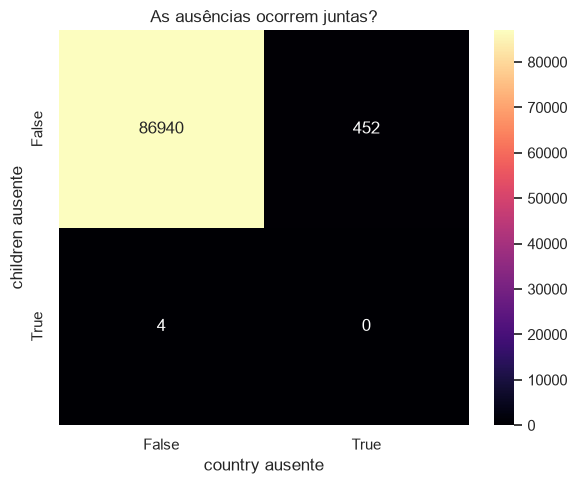

In [10]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

# Resposta

### As ausências ocorrem juntas?

Vamos verificar especificamente `agent` e `company`, que concentram a maior quantidade de valores ausentes:

```python
duas_ausentes = df[["agent", "company"]].isna().all(axis=1).sum()

esperado_independencia = (
    df["agent"].isna().mean()
    * df["company"].isna().mean()
    * len(df)
)

print("Ausências simultâneas:", duas_ausentes)
print("Esperado se fossem independentes:", round(esperado_independencia))
```

Resultado:

```text
Ausências simultâneas: 9760
Esperado se fossem independentes: 15410
```

**Discussão:** As ausências não parecem independentes, pois a quantidade observada é bem menor que a esperada sob independência. Pelo conhecimento de domínio, esses valores representam principalmente situações em que a reserva não envolveu uma agência ou empresa. A própria documentação original afirma que esses `NULL` significam “não aplicável”, e não uma falha de coleta. [Artigo original](https://repositorio.iscte-iul.pt/bitstream/10071/16929/1/Hotelbookingdemanddatasets.pdf)

Assim, o mecanismo não parece **MCAR** nem propriamente **MNAR**. A interpretação mais adequada é uma ausência estrutural ou, dentro das três classificações, **MAR**, pois está associada a características observáveis da reserva, como o canal de distribuição.

## 3. Princípio Distribucional

Ainda com os dados originais, sem tratar ausências ou outliers, vamos analisar as distribuições. Esse retrato inicial ajudará a decidir tratamentos como imputação pela média ou mediana.

In [11]:
VARS_QUANT = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

VARS_QUALI = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "is_repeated_guest",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "agent",
    "company",
    "customer_type",
    "status_reserva"
]


# Tabela descritiva, com assimetria e curtose


desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style
    .format(precision=2)
    .background_gradient(
        cmap="magma",
        subset=["skewness", "kurtosis"]
    )
)

,mean,median,std,min,max,skewness,kurtosis
lead_time,79.89,49.00,86.05,0.00,737.00,1.43,2.13
stays_in_weekend_nights,1.01,1.00,1.03,0.00,19.00,1.41,7.99
stays_in_week_nights,2.63,2.00,2.05,0.00,50.00,2.69,22.10
adults,1.88,2.00,0.63,0.00,55.00,19.86,1347.15
children,0.14,0.00,0.46,0.00,10.00,3.46,12.96
babies,0.01,0.00,0.11,0.00,10.00,21.15,1205.09
previous_cancellations,0.03,0.00,0.37,0.00,26.00,34.32,1726.09
previous_bookings_not_canceled,0.18,0.00,1.73,0.00,72.00,20.46,579.40
booking_changes,0.27,0.00,0.73,0.00,21.00,5.55,67.62
days_in_waiting_list,0.75,0.00,10.02,0.00,391.00,19.40,480.61


**Pra discutir:** Todas as variáveis quantitativas apresentam assimetria positiva (skewness > 1), ou seja, possuem cauda à direita. As maiores assimetrias aparecem em babies, previous_cancellations, previous_bookings_not_canceled, adults, days_in_waiting_list e adr.

Quase todas também apresentam caudas pesadas (kurtosis > 2), exceto lead_time e total_of_special_requests.

Isso é coerente com o contexto hoteleiro: a maioria das reservas possui poucos hóspedes, crianças, alterações, cancelamentos anteriores e dias de espera, enquanto poucos registros apresentam valores muito elevados. Entretanto, curtoses extremamente altas em adults e adr também podem indicar valores atípicos ou erros de registro, que deverão ser investigados antes do tratamento.

### Distribuições dos dados

Primeiro, observamos a distribuição geral das variáveis quantitativas. Em seguida, comparamos as reservas “Não canceladas” (verde-azulado) e “Canceladas” (coral).

Para melhorar a visualização, os gráficos apresentam os dados entre os percentis 0,5% e 99,5%, evitando que valores extremos comprimam as distribuições. Esse recorte é apenas visual e não altera o DataFrame original.

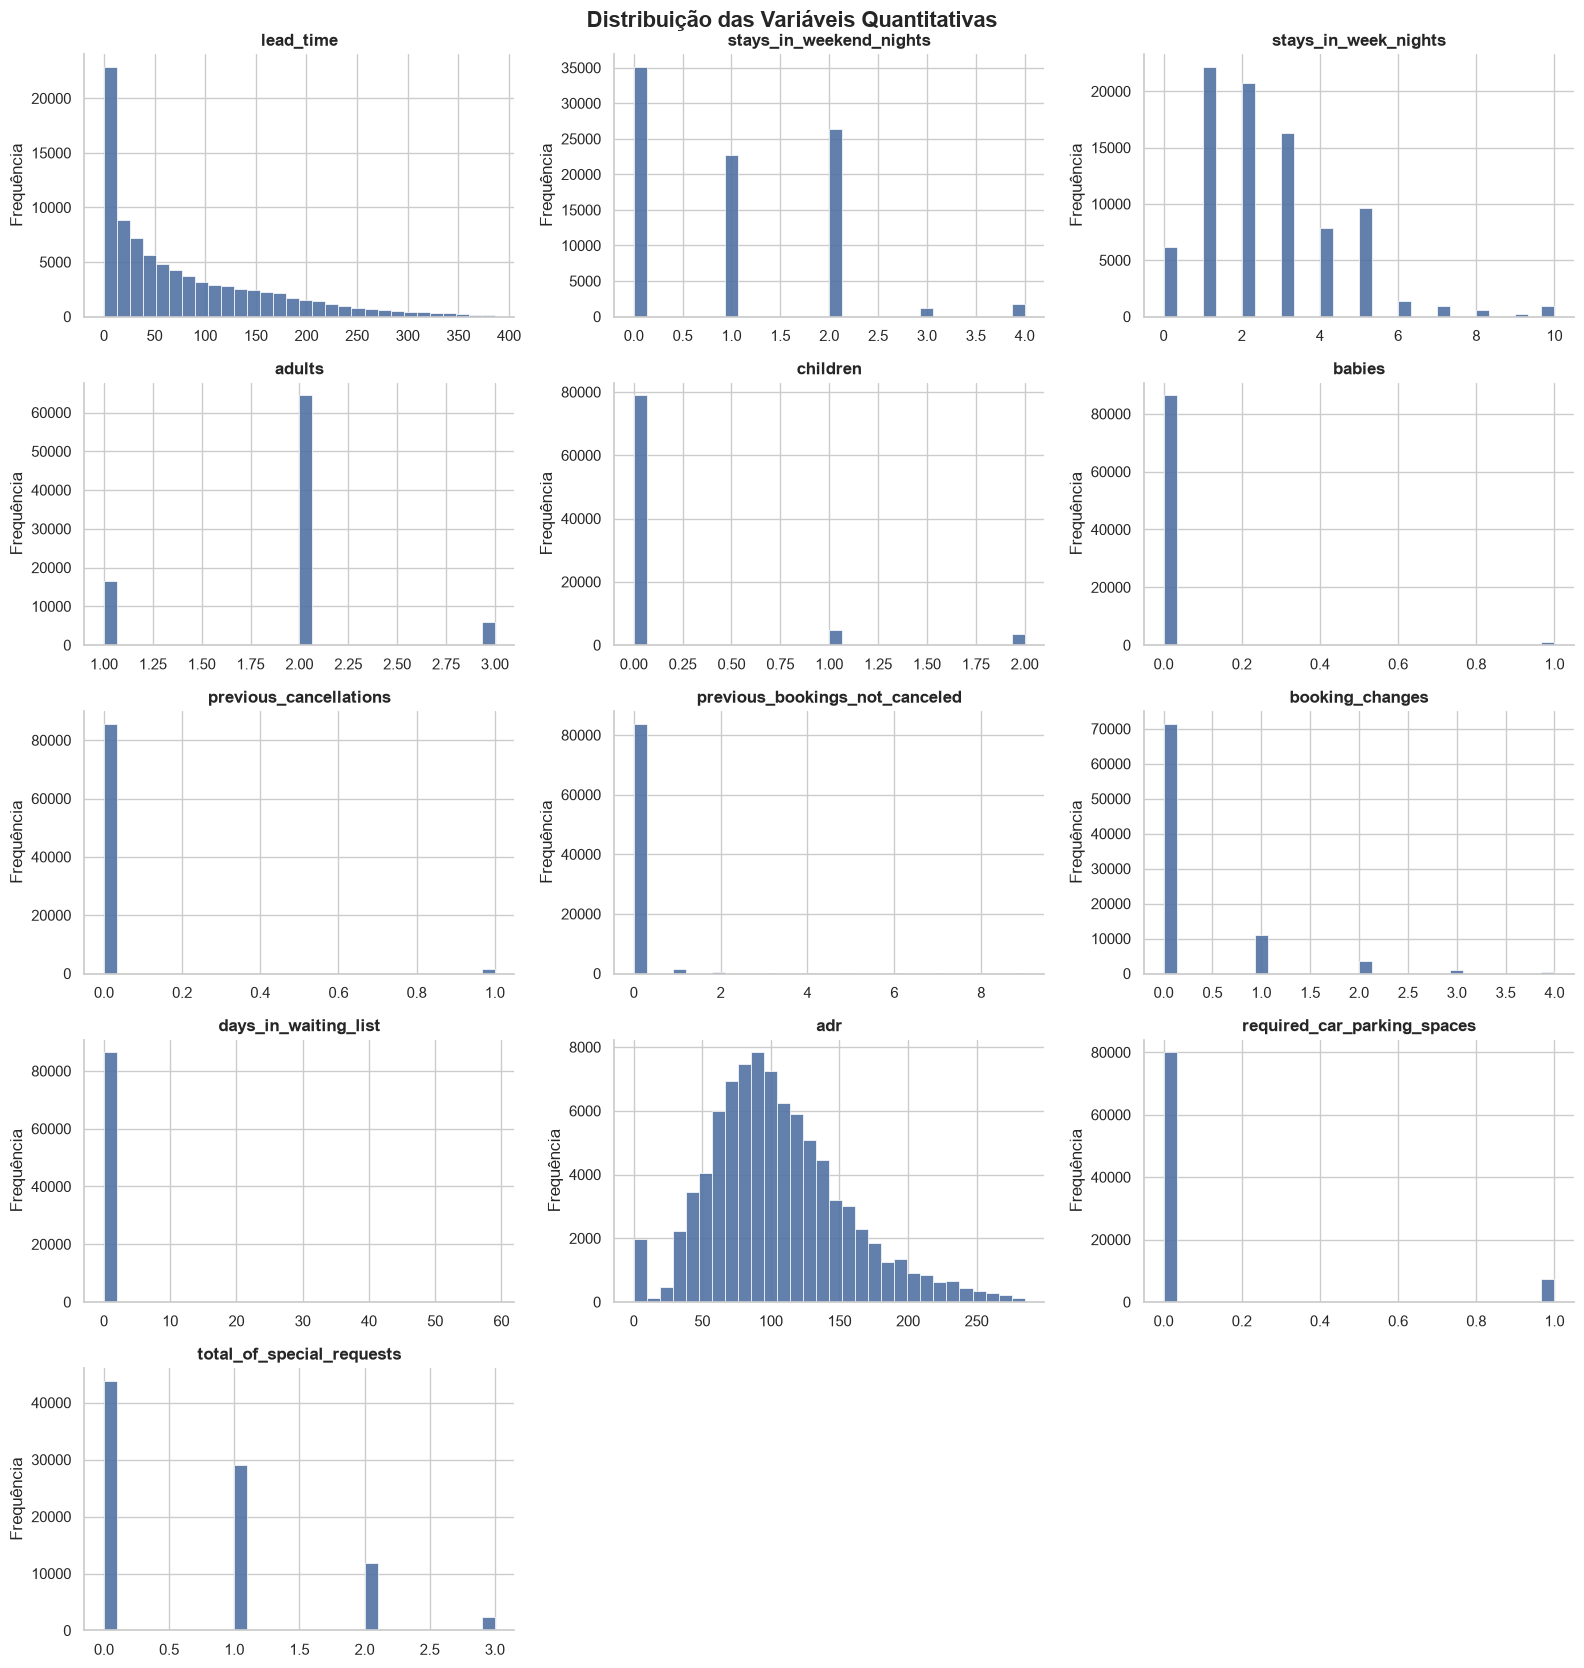

In [12]:
sns.set_theme(style="whitegrid")

COR_DISTRIBUICAO = "#5271A3"

n_colunas = 3
n_linhas = (len(VARS_QUANT) + n_colunas - 1) // n_colunas

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 3.4 * n_linhas)
)

axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    limite_inferior = df[col].quantile(0.005)
    limite_superior = df[col].quantile(0.995)

    dados = df.loc[
        df[col].between(limite_inferior, limite_superior),
        col
    ].dropna()

    sns.histplot(
        dados,
        bins=30,
        color=COR_DISTRIBUICAO,
        edgecolor="white",
        linewidth=0.5,
        alpha=0.9,
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequência")
    sns.despine(ax=axes[i])

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

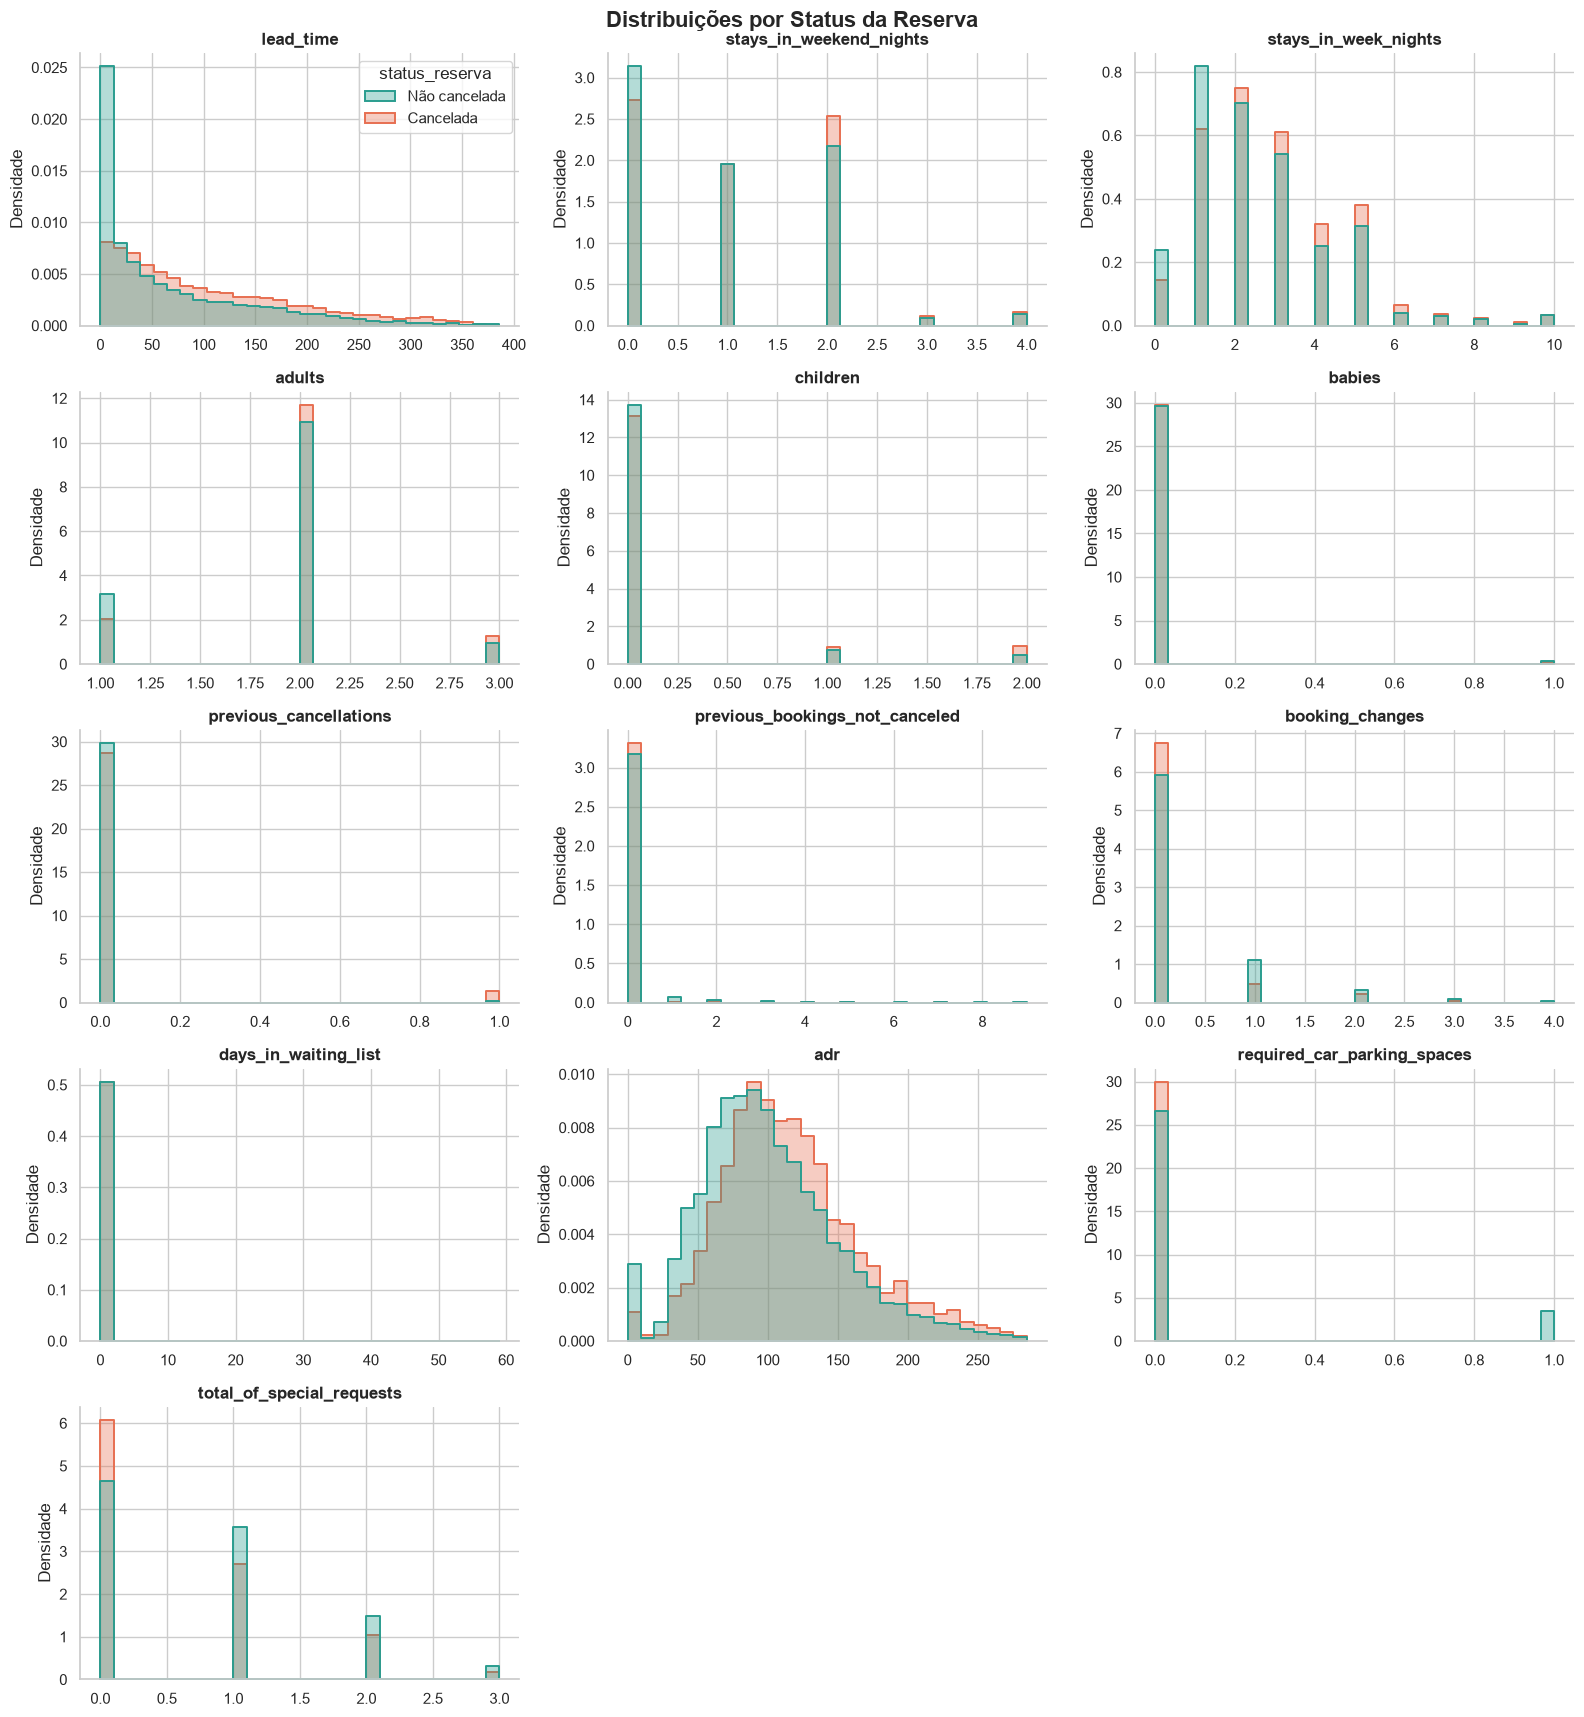

In [13]:
CORES_STATUS = {
    "Não cancelada": "#2A9D8F",
    "Cancelada": "#E76F51"
}

n_colunas = 3
n_linhas = (len(VARS_QUANT) + n_colunas - 1) // n_colunas

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 3.5 * n_linhas)
)

axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    limite_inferior = df[col].quantile(0.005)
    limite_superior = df[col].quantile(0.995)

    dados = df[
        df[col].between(limite_inferior, limite_superior)
    ].copy()

    sns.histplot(
        data=dados,
        x=col,
        hue="status_reserva",
        hue_order=["Não cancelada", "Cancelada"],
        palette=CORES_STATUS,
        bins=30,
        stat="density",
        common_norm=False,
        multiple="layer",
        element="step",
        fill=True,
        alpha=0.35,
        linewidth=1.4,
        ax=axes[i],
        legend=(i == 0)
    )

    axes[i].set_title(col, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densidade")
    sns.despine(ax=axes[i])

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Distribuições por Status da Reserva",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Para discutir:** agora que as distribuições de reservas “Não canceladas” e “Canceladas” estão sobrepostas, normalizadas por densidade e apresentadas na mesma escala, quais variáveis exibem formatos ou concentrações diferentes entre os dois grupos? Observe especialmente possíveis diferenças em `lead_time`, `adr`, `previous_cancellations` e `total_of_special_requests`.

#### Testes de aderência

*Será que a tarifa média diária (adr) segue uma distribuição normal?*

Vamos utilizar o teste de **Shapiro-Wilk** e o **QQ-Plot**. Como o dataset possui mais de 119 mil registros, usamos uma amostra reproduzível de 5.000 observações.

Shapiro-Wilk — adr: estatística=0.9594, p-valor=2.934e-35
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


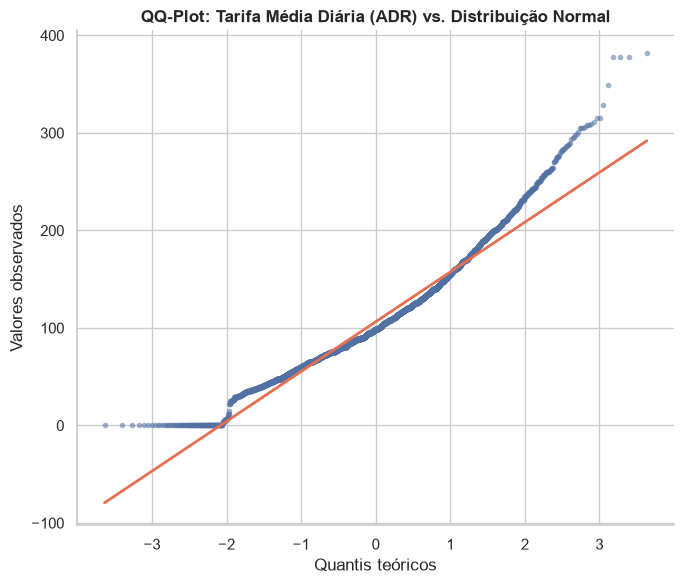

In [14]:
adr = df["adr"].dropna()

amostra_adr = adr.sample(
    n=min(5000, len(adr)),
    random_state=42
)

stat_sw, p_valor_sw = stats.shapiro(amostra_adr)

print(
    f"Shapiro-Wilk — adr: estatística={stat_sw:.4f}, "
    f"p-valor={p_valor_sw:.4g}"
)

print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw < 0.05 else "Não",
    "(alpha = 0.05)"
)

"""### QQ-Plot — colesterol"""

fig, ax = plt.subplots(figsize=(7, 6))

stats.probplot(amostra_adr, dist="norm", plot=ax)

pontos, reta = ax.get_lines()

pontos.set(
    markerfacecolor="#5271A3",
    markeredgecolor="none",
    markersize=4,
    alpha=0.55
)

reta.set(
    color="#E76F51",
    linewidth=2
)

ax.set_title(
    "QQ-Plot: Tarifa Média Diária (ADR) vs. Distribuição Normal",
    fontweight="bold"
)

ax.set_xlabel("Quantis teóricos")
ax.set_ylabel("Valores observados")

sns.despine()
plt.tight_layout()
plt.show()

**Como ler:** se os pontos acompanhassem a reta, adr apresentaria comportamento próximo ao normal. Afastamentos nas extremidades indicam assimetria, caudas pesadas ou possíveis valores atípicos.


**Cuidados de interpretação:**

- Com uma amostra grande, o Shapiro-Wilk possui alto poder e pode rejeitar a normalidade mesmo diante de pequenos desvios. Por isso, o resultado deve ser analisado junto ao QQ-Plot, à assimetria e à curtose.
- Quando p < 0.05, temos evidência contra a normalidade. Quando p ≥ 0.05, apenas não encontramos evidência suficiente para rejeitá-la.
- Para variáveis de contagem com muitos zeros, como babies e previous_cancellations, a rejeição da normalidade já é esperada.

In [15]:
resultados_shapiro = []

for col in VARS_QUANT:
    serie = df[col].dropna()

    amostra = serie.sample(
        n=min(5000, len(serie)),
        random_state=42
    )

    stat, p = stats.shapiro(amostra)

    resultados_shapiro.append({
        "variavel": col,
        "estatistica": stat,
        "p_valor": p,
        "rejeita_normalidade": p < 0.05
    })

(
    pd.DataFrame(resultados_shapiro)
    .set_index("variavel")
    .style
    .format({
        "estatistica": "{:.4f}",
        "p_valor": "{:.3e}"
    })
)

,estatistica,p_valor,rejeita_normalidade
variavel,,,
lead_time,0.8471,1.285e-56,True
stays_in_weekend_nights,0.7514,9.130e-66,True
stays_in_week_nights,0.7460,3.434e-66,True
adults,0.6891,3.259e-70,True
children,0.3391,2.682e-86,True
babies,0.0792,6.566e-94,True
previous_cancellations,0.0927,1.462e-93,True
previous_bookings_not_canceled,0.0921,1.408e-93,True
booking_changes,0.4414,1.449e-82,True


### ECDF — outra forma de observar a distribuição

Diferentemente do histograma, a ECDF não depende da escolha de *bins*. Para cada valor no eixo X, a curva mostra a proporção acumulada de observações menores ou iguais àquele valor.

Vamos analisar `lead_time`, que representa a quantidade de dias entre a realização da reserva e a chegada ao hotel.

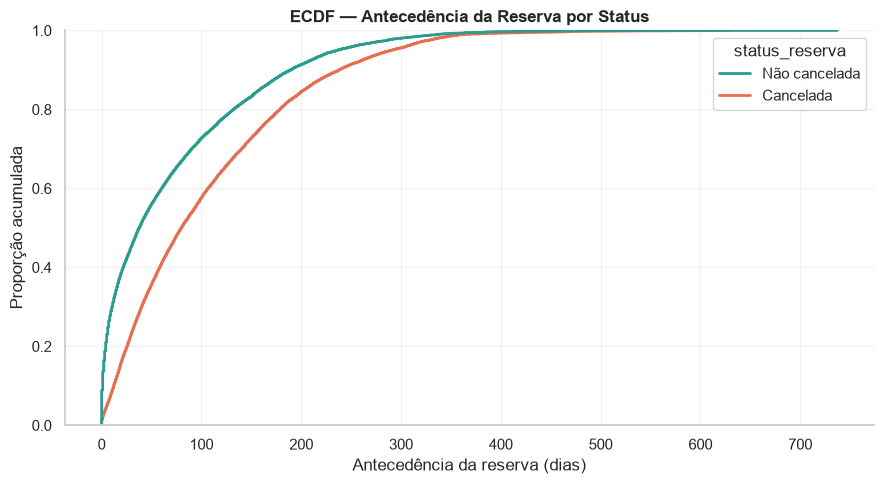

In [16]:
plt.figure(figsize=(9, 5))

sns.ecdfplot(
    data=df,
    x="lead_time",
    hue="status_reserva",
    hue_order=["Não cancelada", "Cancelada"],
    palette=CORES_STATUS,
    linewidth=2
)

plt.title(
    "ECDF — Antecedência da Reserva por Status",
    fontweight="bold"
)

plt.xlabel("Antecedência da reserva (dias)")
plt.ylabel("Proporção acumulada")
plt.grid(alpha=0.25)
sns.despine()
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva indica a proporção de reservas realizadas com até aquela quantidade de dias de antecedência.

Quando a curva das reservas canceladas aparece deslocada para a direita, isso indica que elas costumam ser realizadas com maior antecedência. A região em que as duas curvas mais se distanciam representa a faixa de `lead_time` na qual a diferença entre reservas canceladas e não canceladas é mais evidente.

### Métricas de Tendência Central

Vamos comparar a média e a mediana de `adr`, que representa a tarifa média diária da reserva.


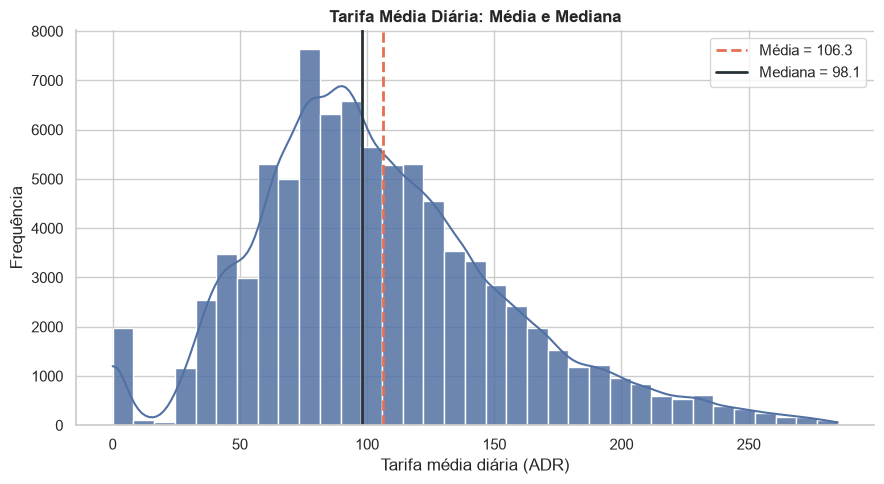

In [17]:
dados_adr = df["adr"].dropna()

media_adr = dados_adr.mean()
mediana_adr = dados_adr.median()

limite_inferior = dados_adr.quantile(0.005)
limite_superior = dados_adr.quantile(0.995)

dados_visualizacao = dados_adr[
    dados_adr.between(limite_inferior, limite_superior)
]

plt.figure(figsize=(9, 5))

sns.histplot(
    dados_visualizacao,
    bins=35,
    kde=True,
    color="#5271A3",
    edgecolor="white",
    alpha=0.85
)

plt.axvline(
    media_adr,
    color="#E76F51",
    linestyle="--",
    linewidth=2,
    label=f"Média = {media_adr:.1f}"
)

plt.axvline(
    mediana_adr,
    color="#263238",
    linewidth=2,
    label=f"Mediana = {mediana_adr:.1f}"
)

plt.title(
    "Tarifa Média Diária: Média e Mediana",
    fontweight="bold"
)

plt.xlabel("Tarifa média diária (ADR)")
plt.ylabel("Frequência")
plt.legend()
sns.despine()
plt.tight_layout()
plt.show()

### Dispersão

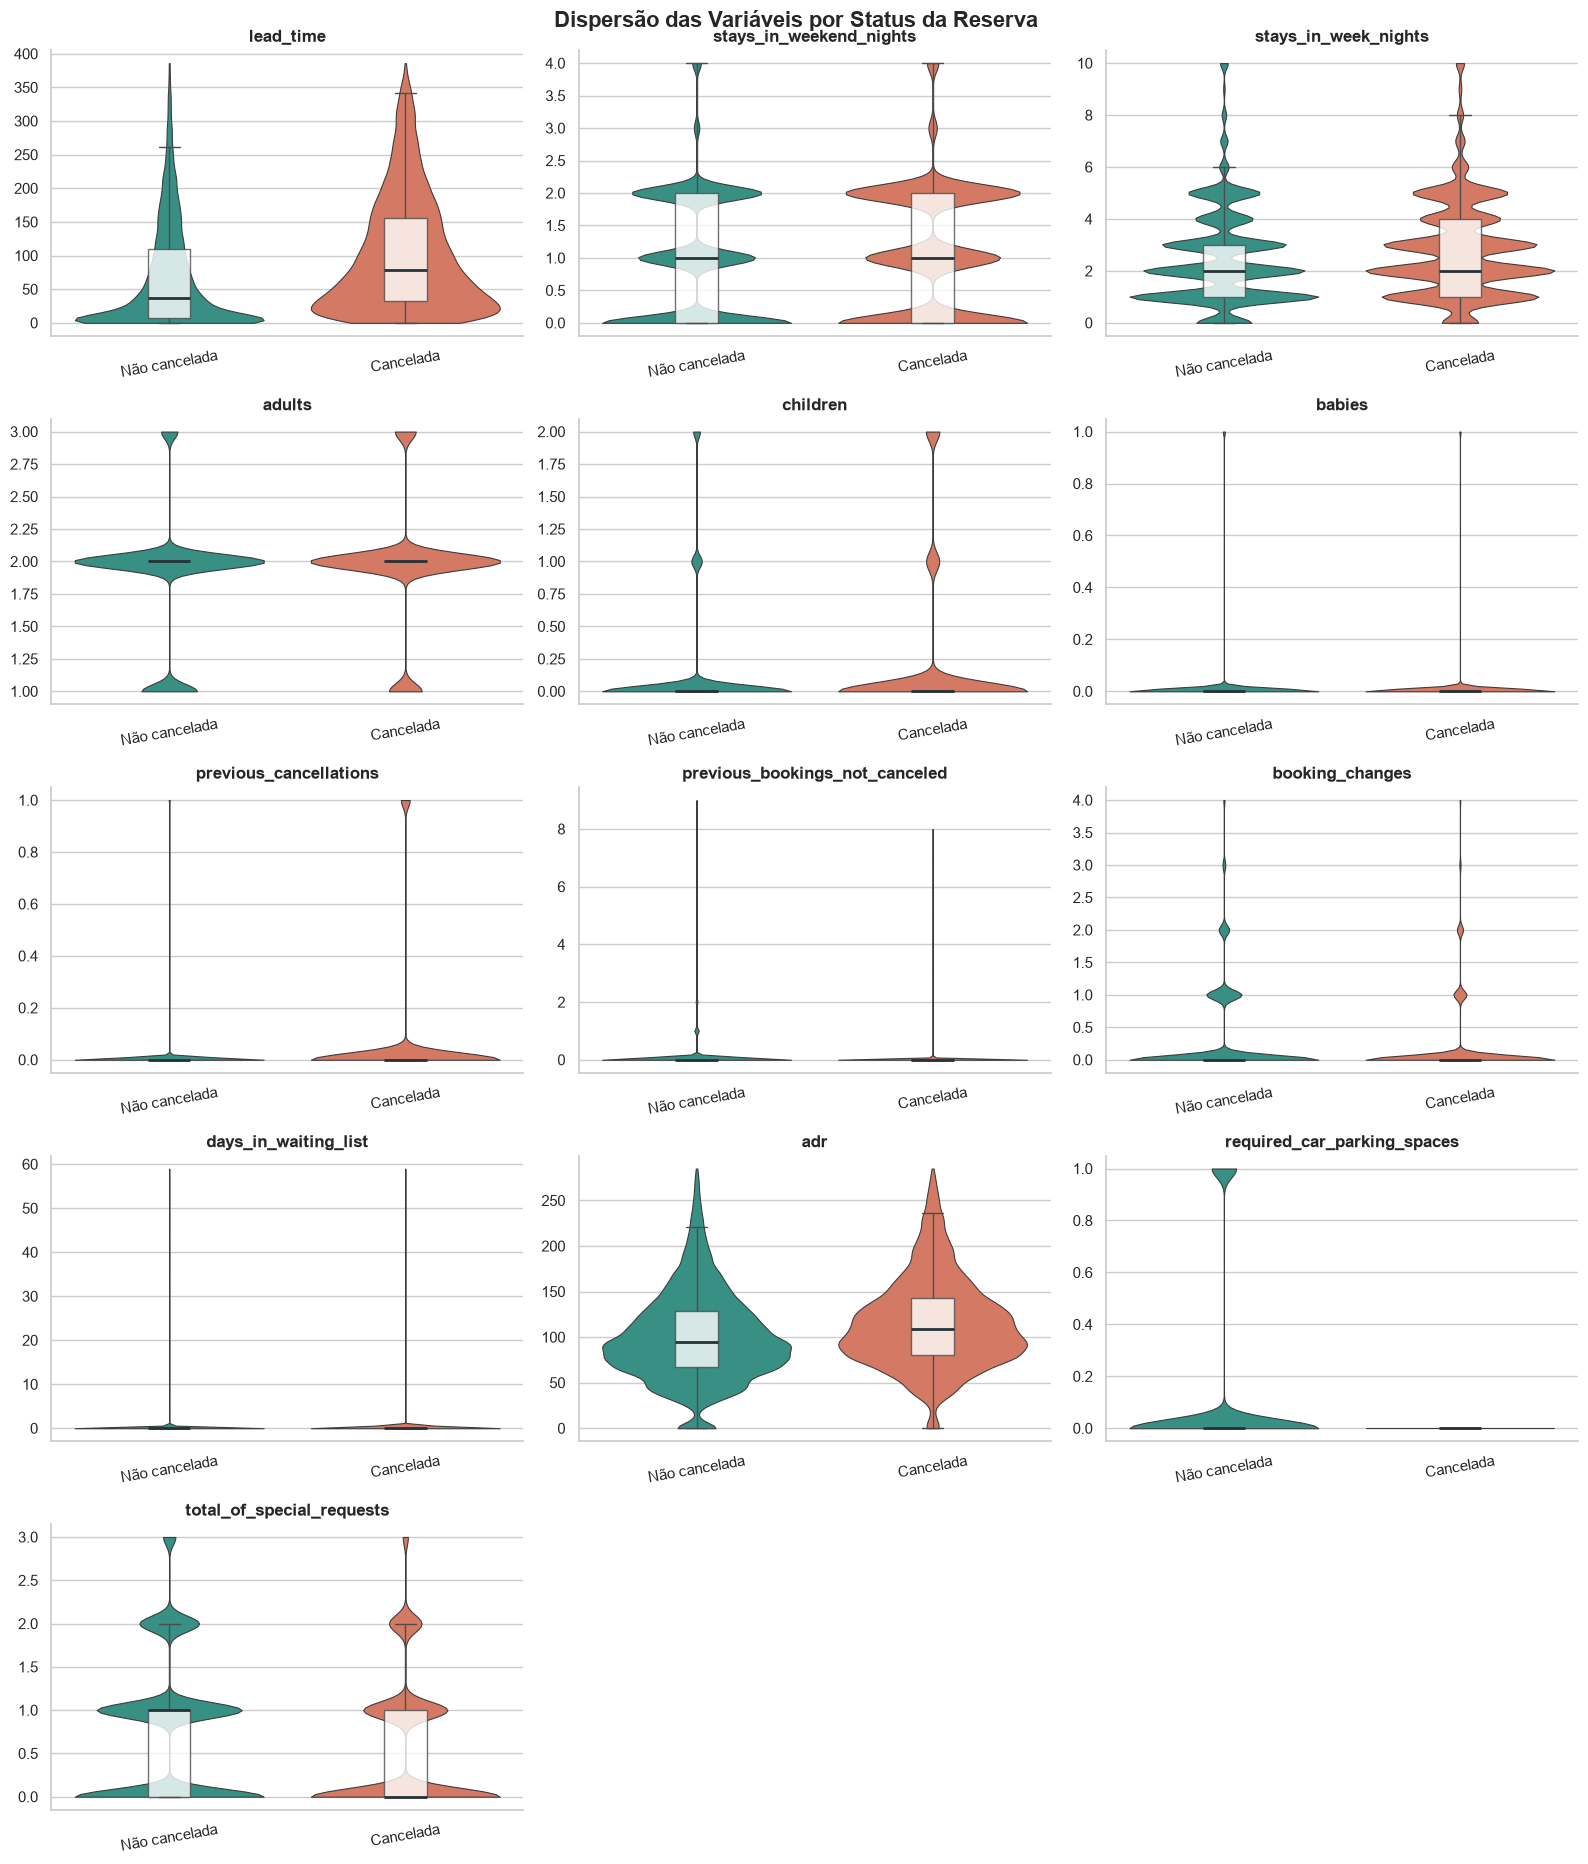

In [18]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T

dispersao["IQR"] = (
    df[VARS_QUANT].quantile(0.75)
    - df[VARS_QUANT].quantile(0.25)
)

dispersao.round(2)

'''### Boxplot e violin plot por status da reserva'''

palette_classe = {
    "Não cancelada": "#2A9D8F",
    "Cancelada": "#E76F51"
}

ordem_classes = ["Não cancelada", "Cancelada"]

n_colunas = 3
n_linhas = (len(VARS_QUANT) + n_colunas - 1) // n_colunas

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 3.8 * n_linhas)
)

axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    limite_inferior = df[col].quantile(0.005)
    limite_superior = df[col].quantile(0.995)

    dados_plot = df.loc[
        df[col].between(limite_inferior, limite_superior),
        ["status_reserva", col]
    ].dropna()

    sns.violinplot(
        data=dados_plot,
        x="status_reserva",
        y=col,
        hue="status_reserva",
        order=ordem_classes,
        hue_order=ordem_classes,
        palette=palette_classe,
        inner=None,
        cut=0,
        linewidth=0.8,
        dodge=False,
        legend=False,
        ax=axes[i]
    )

    sns.boxplot(
        data=dados_plot,
        x="status_reserva",
        y=col,
        hue="status_reserva",
        order=ordem_classes,
        hue_order=ordem_classes,
        width=0.18,
        showfliers=False,
        dodge=False,
        legend=False,
        boxprops={"facecolor": "white", "alpha": 0.8},
        medianprops={"color": "#263238", "linewidth": 2},
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight="bold")
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis="x", rotation=10)
    sns.despine(ax=axes[i])

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Dispersão das Variáveis por Status da Reserva",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Para discutir:** alguma variável apresenta mediana ou intervalo interquartil claramente diferente entre reservas canceladas e não canceladas? Observe especialmente `lead_time`, `adr`, `previous_cancellations` e `total_of_special_requests`. Essas diferenças podem indicar variáveis úteis para explicar ou prever cancelamentos, mas ainda precisam ser confirmadas pela análise bivariada.

## 4. Tratamento de Dados Ausentes e Outliers

Após o retrato estatístico inicial, podemos decidir como tratar os valores ausentes em `children`, `country`, `agent` e `company`, além dos possíveis outliers das variáveis quantitativas.

Depois do tratamento, as estatísticas descritivas serão calculadas novamente para avaliar o efeito das decisões tomadas.



### Detecção de outliers por IQR

A regra do IQR classifica como possível outlier qualquer valor fora do intervalo:

`[Q1 - 1,5 × IQR, Q3 + 1,5 × IQR]`



In [19]:
def limites_iqr(serie):
    serie = serie.dropna()

    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1

    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


resumo_outliers = {}

for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])

    mascara_outlier = (
        (df[col] < lim_inf)
        | (df[col] > lim_sup)
    )

    n_outliers = mascara_outlier.sum()

    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
        "percentual": round(100 * n_outliers / len(df), 2)
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,percentual
lead_time,-160.0,296.0,2396.0,2.74
stays_in_weekend_nights,-3.0,5.0,220.0,0.25
stays_in_week_nights,-3.5,8.5,1531.0,1.75
adults,2.0,2.0,22899.0,26.20
children,0.0,0.0,8364.0,9.57
babies,0.0,0.0,914.0,1.05
previous_cancellations,0.0,0.0,1685.0,1.93
previous_bookings_not_canceled,0.0,0.0,3545.0,4.06
booking_changes,0.0,0.0,15902.0,18.20
days_in_waiting_list,0.0,0.0,860.0,0.98


### Visualizando os Outliers

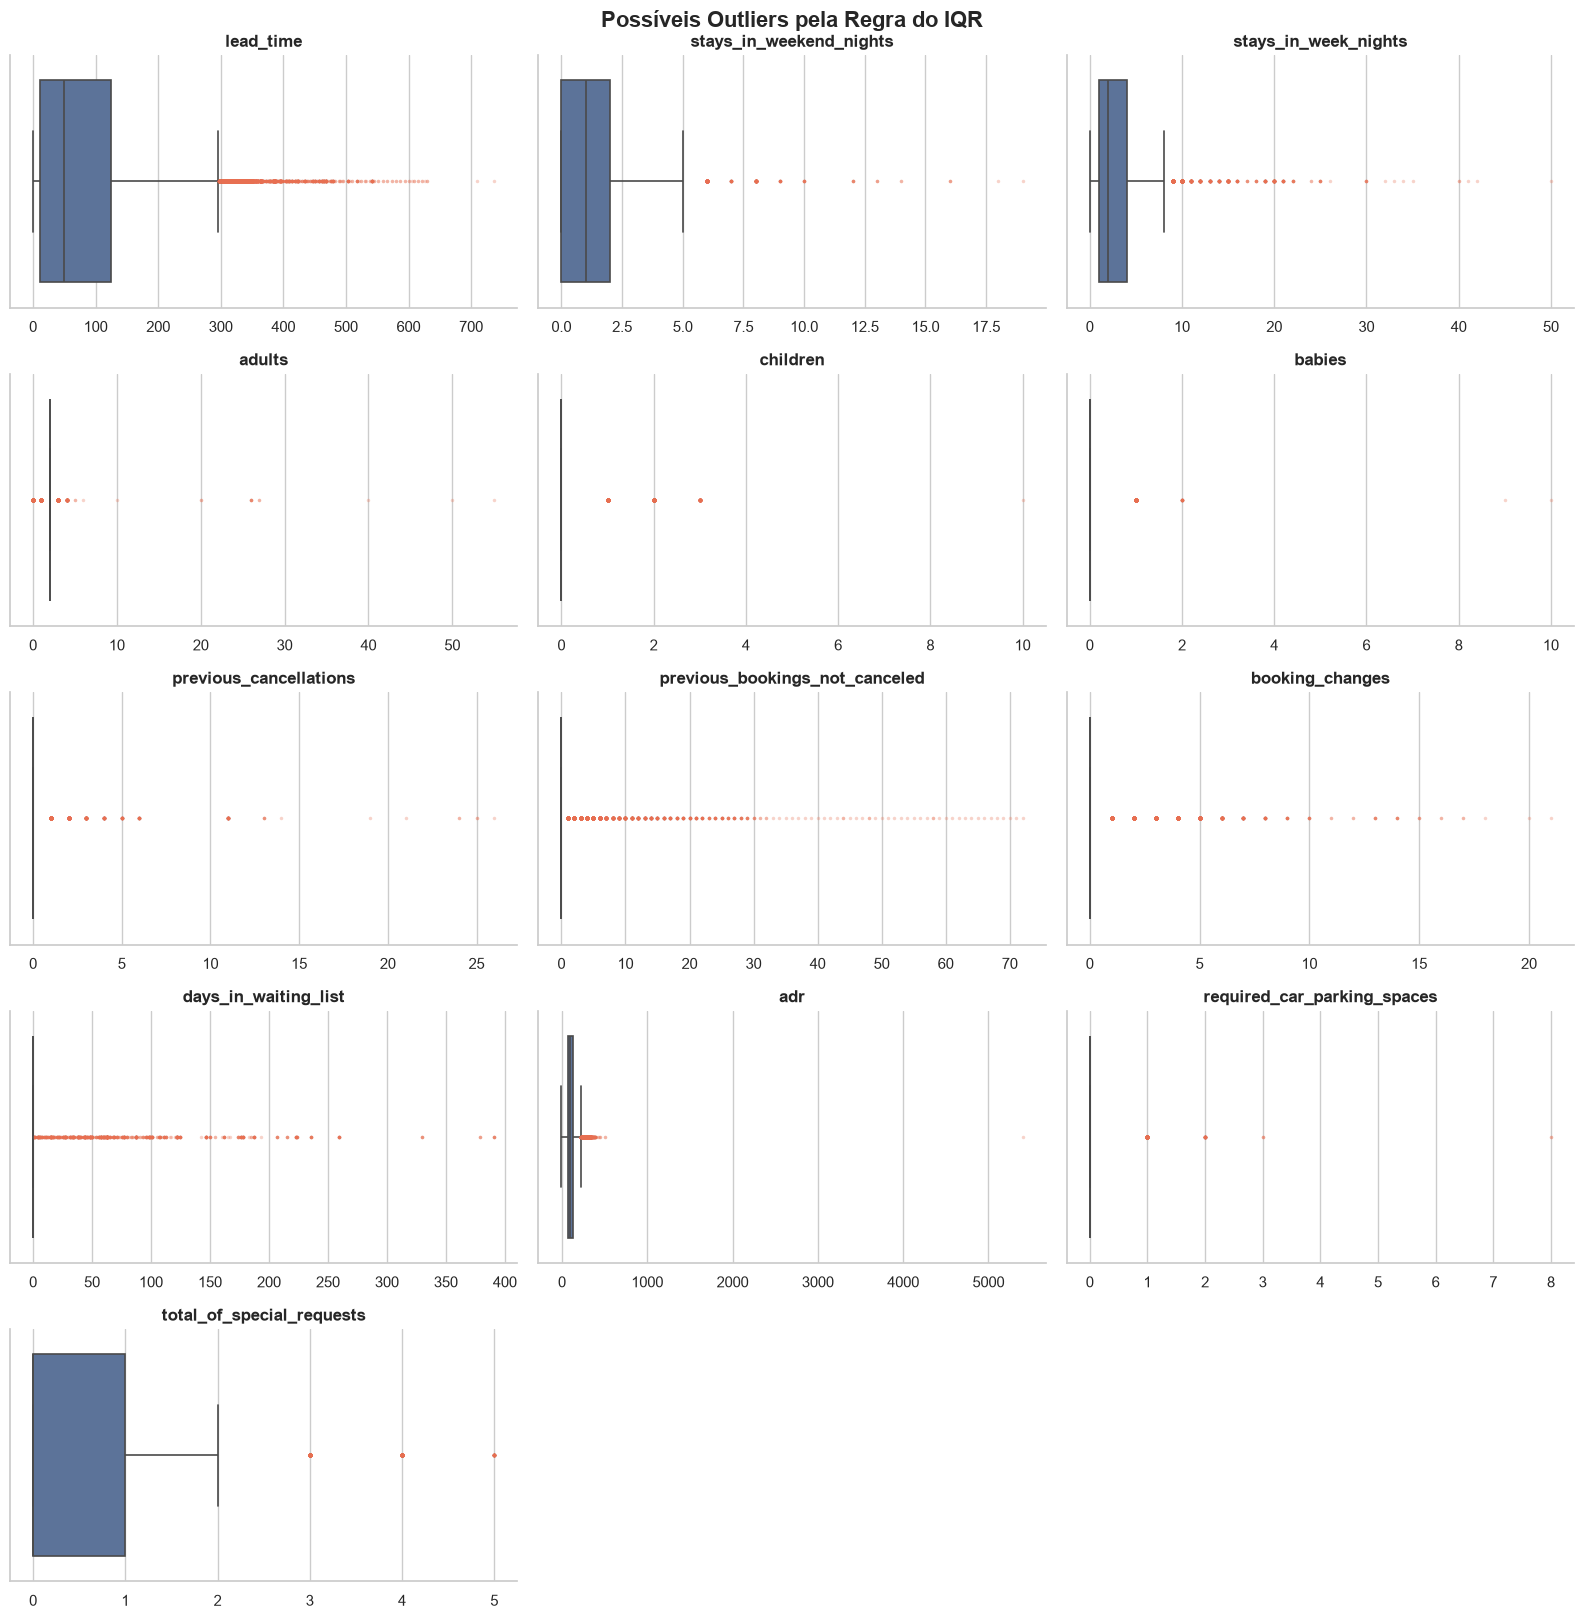

In [20]:
n_colunas = 3
n_linhas = (len(VARS_QUANT) + n_colunas - 1) // n_colunas

fig, axes = plt.subplots(
    n_linhas,
    n_colunas,
    figsize=(16, 3.3 * n_linhas)
)

axes = axes.ravel()

estilo_outliers = {
    "marker": "o",
    "markerfacecolor": "#E76F51",
    "markeredgecolor": "none",
    "markersize": 2.5,
    "alpha": 0.3
}

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(
        data=df,
        x=col,
        color="#5271A3",
        linewidth=1.2,
        flierprops=estilo_outliers,
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight="bold")
    axes[i].set_xlabel("")
    sns.despine(ax=axes[i])

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle(
    "Possíveis Outliers pela Regra do IQR",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Para discutir

| Tipo | Cenário | Tratamento possível |
|---|---|---|
| Estatístico | Valor incomum, mas legítimo | Manter ou transformar |
| De domínio | Viola uma regra do negócio | Investigar |
| Erro de dados | Valor registrado incorretamente | Corrigir ou remover |

A regra do IQR deve ser interpretada com cuidado neste dataset:

- Valores elevados de `lead_time` podem representar reservas feitas com muita antecedência e ainda serem legítimos.
- Tarifas `adr` muito altas podem representar hospedagens especiais, mas valores negativos devem ser investigados.
- Uma reserva com muitos adultos pode ser de grupo ou erro de registro.
- Em variáveis com muitos zeros, como `babies`, `previous_cancellations` e `required_car_parking_spaces`, o IQR pode ser zero e classificar qualquer valor positivo como outlier.

Portanto, um outlier estatístico não deve ser removido automaticamente. Primeiro é necessário verificar se o valor é plausível no contexto das reservas de hotéis.


### Decidindo o tratamento dos dados ausentes

As decisões serão:

- `children`: preencher com zero;
- `country`: preencher com `"Unknown"`;
- `agent` e `company`: preencher com zero, representando “não aplicável”, e transformar em categorias.



In [21]:
linhas_antes = df.shape[0]
df_antes = df.copy()

df["children"] = df["children"].fillna(0)

df["country"] = df["country"].fillna("Unknown")

df["agent"] = (
    df["agent"]
    .fillna(0)
    .astype("Int64")
    .astype("category")
)

df["company"] = (
    df["company"]
    .fillna(0)
    .astype("Int64")
    .astype("category")
)

linhas_depois = df.shape[0]

print(
    f"Linhas antes: {linhas_antes} | "
    f"Linhas depois: {linhas_depois} | "
    f"Removidas: {linhas_antes - linhas_depois}"
)

print("\nAusências restantes:")
print(df.isna().sum()[df.isna().sum() > 0])

Linhas antes: 87396 | Linhas depois: 87396 | Removidas: 0

Ausências restantes:
Series([], dtype: int64)



### Decidindo o tratamento dos outliers

Os outliers estatísticos não serão removidos automaticamente. Reservas com grande antecedência, tarifas elevadas ou muitos hóspedes podem ser incomuns, mas legítimas.

Entretanto, duas situações violam regras básicas do negócio:

- uma reserva não pode possuir tarifa diária negativa;
- uma reserva não deve possuir zero hóspedes.

No dataset, há 1 registro com `adr` negativo e 166 reservas sem hóspedes, totalizando 167 registros inválidos.



In [22]:
total_hospedes = (
    df["adults"]
    + df["children"]
    + df["babies"]
)

adr_negativo = df["adr"] < 0
sem_hospedes = total_hospedes == 0

print("ADR negativo:", adr_negativo.sum())
print("Reservas sem hóspedes:", sem_hospedes.sum())

registros_invalidos = adr_negativo | sem_hospedes

linhas_antes_outliers = len(df)

df = (
    df.loc[~registros_invalidos]
    .reset_index(drop=True)
)

print(
    f"Linhas antes: {linhas_antes_outliers} | "
    f"Linhas depois: {len(df)} | "
    f"Removidas: {registros_invalidos.sum()}"
)

ADR negativo: 1
Reservas sem hóspedes: 166
Linhas antes: 87396 | Linhas depois: 87229 | Removidas: 167


Os demais valores extremos serão mantidos. Como demonstração, podemos aplicar uma transformação logarítmica em adr para reduzir sua assimetria.

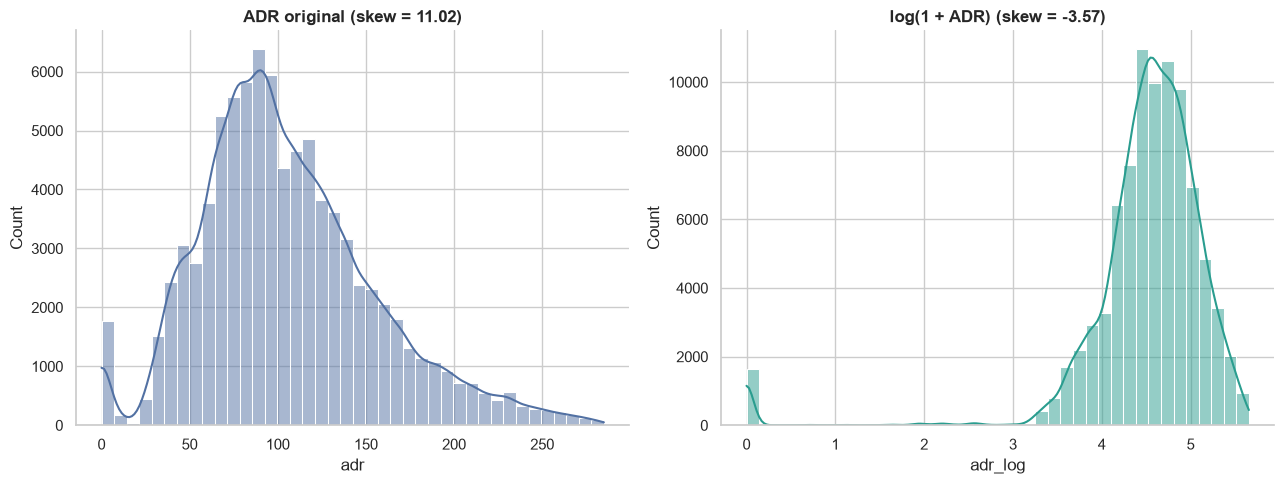

In [23]:
df["adr_log"] = np.log1p(df["adr"])

limite_superior = df["adr"].quantile(0.995)
dados_plot = df[df["adr"] <= limite_superior]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=dados_plot,
    x="adr",
    bins=40,
    kde=True,
    color="#5271A3",
    ax=axes[0]
)

axes[0].set_title(
    f"ADR original (skew = {df['adr'].skew():.2f})",
    fontweight="bold"
)

sns.histplot(
    data=dados_plot,
    x="adr_log",
    bins=40,
    kde=True,
    color="#2A9D8F",
    ax=axes[1]
)

axes[1].set_title(
    f"log(1 + ADR) (skew = {df['adr_log'].skew():.2f})",
    fontweight="bold"
)

sns.despine()
plt.tight_layout()
plt.show()


**Para discutir:** a transformação logarítmica reduziu a assimetria de `adr`? Ela preserva todas as observações válidas, mas reduz a influência visual dos valores muito elevados. A coluna `adr_log` será mantida apenas como demonstração e não será utilizada nas próximas análises.

## 5. Estatística Descritiva — Parte 2

Fechando o ciclo iterativo: tratamos os valores ausentes, removemos 167 registros que violavam regras do negócio e mantivemos os outliers considerados plausíveis.

Agora repetimos as estatísticas da Seção 3 para comparar os resultados com o retrato anterior. A coluna `adr_log` não será incluída, pois foi criada apenas como demonstração.



In [24]:
desc_depois = df[VARS_QUANT].describe().T

desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[
        ["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]
    ]
    .rename(columns={"50%": "median"})
    .round(2)
    .style
    .format(precision=2)
    .background_gradient(
        cmap="Blues",
        subset=["skewness", "kurtosis"]
    )
)

,mean,median,std,min,max,skewness,kurtosis
lead_time,79.97,49.00,86.06,0.00,737.00,1.43,2.12
stays_in_weekend_nights,1.00,1.00,1.03,0.00,19.00,1.34,7.08
stays_in_week_nights,2.62,2.00,2.04,0.00,50.00,2.58,20.10
adults,1.88,2.00,0.62,0.00,55.00,20.39,1391.13
children,0.14,0.00,0.46,0.00,10.00,3.46,12.92
babies,0.01,0.00,0.11,0.00,10.00,21.13,1202.81
previous_cancellations,0.03,0.00,0.37,0.00,26.00,34.33,1725.62
previous_bookings_not_canceled,0.18,0.00,1.73,0.00,72.00,20.46,578.97
booking_changes,0.27,0.00,0.71,0.00,18.00,5.07,54.00
days_in_waiting_list,0.75,0.00,10.00,0.00,391.00,19.47,483.81


### Comparando "antes"x "depois""



In [25]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"]
})

comparacao["delta_skewness"] = (
    comparacao["skewness_depois"]
    - comparacao["skewness_antes"]
)

comparacao["delta_kurtosis"] = (
    comparacao["kurtosis_depois"]
    - comparacao["kurtosis_antes"]
)

comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
lead_time,1.432,1.431,2.126,2.123,-0.001,-0.003
stays_in_weekend_nights,1.412,1.340,7.993,7.075,-0.071,-0.918
stays_in_week_nights,2.691,2.576,22.103,20.097,-0.116,-2.006
adults,19.860,20.394,1347.147,1391.125,0.535,43.978
children,3.464,3.460,12.957,12.925,-0.004,-0.032
babies,21.149,21.128,1205.090,1202.808,-0.020,-2.282
previous_cancellations,34.324,34.329,1726.094,1725.616,0.006,-0.479
previous_bookings_not_canceled,20.460,20.456,579.398,578.968,-0.004,-0.430
booking_changes,5.546,5.070,67.616,53.997,-0.477,-13.619
days_in_waiting_list,19.396,19.467,480.609,483.812,0.071,3.203



**Para discutir:** as estatísticas devem apresentar poucas mudanças, pois apenas 167 de 87.396 registros (após remover as duplicadas) foram removidos, aproximadamente 0,19% do dataset. As alterações mais perceptíveis podem aparecer em `adults`, `children`, `babies` e no valor mínimo de `adr`, pois as remoções envolveram reservas sem hóspedes e uma tarifa negativa.

A permanência de assimetrias e curtoses elevadas é esperada, já que os valores extremos considerados plausíveis foram mantidos. Portanto, a pouca mudança confirma que o tratamento foi conservador e preservou a distribuição original dos dados.

### A tarifa média diária ainda rejeita normalidade?

Vamos repetir o teste de Shapiro-Wilk para `adr`, comparando os dados antes e depois do tratamento. Como o dataset é grande, utilizamos amostras reproduzíveis de 5.000 observações.



In [26]:
adr_antes = df_antes["adr"].dropna()
adr_depois = df["adr"].dropna()

amostra_antes = adr_antes.sample(
    n=min(5000, len(adr_antes)),
    random_state=42
)

amostra_depois = adr_depois.sample(
    n=min(5000, len(adr_depois)),
    random_state=42
)

stat_antes, p_antes = stats.shapiro(amostra_antes)
stat_depois, p_depois = stats.shapiro(amostra_depois)

print(
    f"Shapiro-Wilk (antes)  — adr: "
    f"estatística={stat_antes:.4f}, p-valor={p_antes:.4g}"
)

print(
    f"Shapiro-Wilk (depois) — adr: "
    f"estatística={stat_depois:.4f}, p-valor={p_depois:.4g}"
)

print(
    "Rejeita normalidade depois?",
    "Sim" if p_depois < 0.05 else "Não"
)

Shapiro-Wilk (antes)  — adr: estatística=0.9594, p-valor=2.934e-35
Shapiro-Wilk (depois) — adr: estatística=0.9601, p-valor=5.194e-35
Rejeita normalidade depois? Sim



É esperado que `adr` continue rejeitando a normalidade. O tratamento removeu somente um valor negativo, enquanto tarifas elevadas consideradas plausíveis foram mantidas.



### Visualizando “antes” × “depois”

Vamos comparar as distribuições de `adr` e `lead_time`. Para melhorar a visualização e o desempenho no Colab, usamos uma amostra de até 10.000 registros e o mesmo intervalo de valores nas duas curvas.



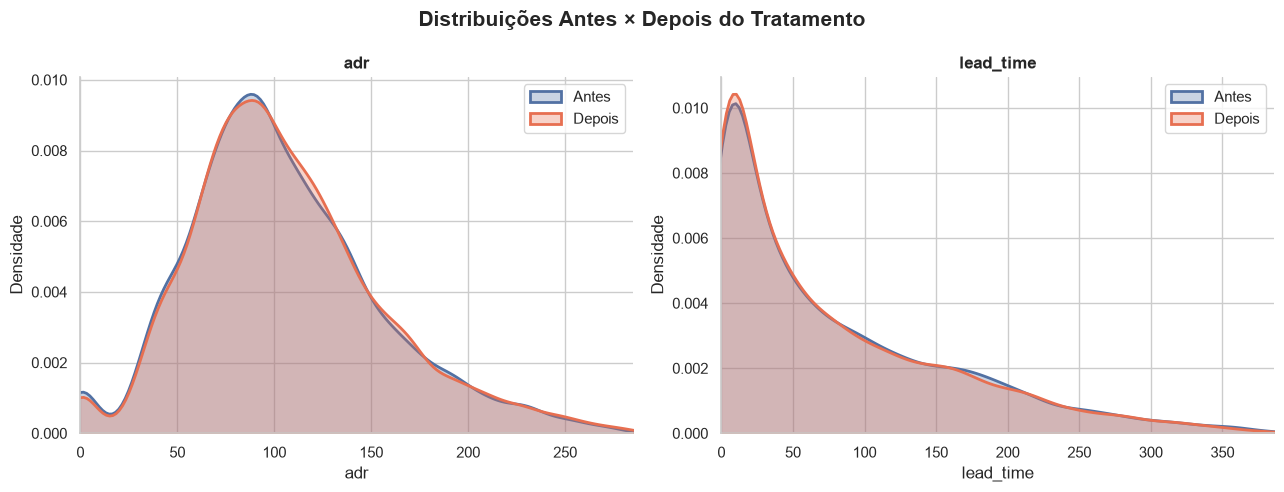

In [27]:
CORES_ETAPA = {
    "Antes": "#5271A3",
    "Depois": "#E76F51"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(axes, ["adr", "lead_time"]):
    lim_inf, lim_sup = df_antes[col].quantile([0.005, 0.995])

    antes = df_antes.loc[
        df_antes[col].between(lim_inf, lim_sup),
        col
    ].dropna()

    depois = df.loc[
        df[col].between(lim_inf, lim_sup),
        col
    ].dropna()

    antes = antes.sample(
        n=min(10000, len(antes)),
        random_state=42
    )

    depois = depois.sample(
        n=min(10000, len(depois)),
        random_state=42
    )

    sns.kdeplot(
        x=antes,
        color=CORES_ETAPA["Antes"],
        fill=True,
        alpha=0.3,
        linewidth=2,
        label="Antes",
        ax=ax
    )

    sns.kdeplot(
        x=depois,
        color=CORES_ETAPA["Depois"],
        fill=True,
        alpha=0.3,
        linewidth=2,
        label="Depois",
        ax=ax
    )

    ax.set_xlim(lim_inf, lim_sup)
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel(col)
    ax.set_ylabel("Densidade")
    ax.legend()
    sns.despine(ax=ax)

fig.suptitle(
    "Distribuições Antes × Depois do Tratamento",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Para discutir:** as curvas devem ficar praticamente sobrepostas. Isso é esperado porque somente 167 registros, aproximadamente 0,19% do dataset, foram removidos, e os outliers plausíveis foram preservados.

Essa comparação confirma que o tratamento corrigiu registros inválidos sem modificar substancialmente a distribuição original dos dados. Em tratamentos mais agressivos, diferenças maiores entre as curvas exigiriam uma investigação cuidadosa.

## 6. Princípio Relacional


### Análise de variáveis qualitativas

Vamos observar a frequência das categorias e possíveis desbalanceamentos. `agent` e `company` são identificadores, não categorias de perfil; por isso, ficam fora dos gráficos e das métricas de equilíbrio.




#### Frequências absolutas e relativas

Para evitar tabelas enormes em variáveis como `country`, mostramos as dez categorias mais frequentes.



In [28]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts(dropna=False)
    freq_rel = df[col].value_counts(normalize=True, dropna=False)

    print(f"\n--- {col} ---")
    display(
        pd.DataFrame({
            "absoluta": freq_abs,
            "relativa (%)": (freq_rel * 100).round(2)
        }).head(10)
    )


--- hotel ---


,absoluta,relativa (%)
hotel,,
City Hotel,53274,61.07
Resort Hotel,33955,38.93



--- arrival_date_month ---


,absoluta,relativa (%)
arrival_date_month,,
August,11242,12.89
July,10043,11.51
May,8344,9.57
April,7900,9.06
June,7756,8.89
March,7488,8.58
October,6921,7.93
September,6682,7.66
February,6083,6.97



--- meal ---


...

,absoluta,relativa (%)
company,,
0,81992,94.00
40,848,0.97
223,503,0.58
45,237,0.27
153,205,0.24
154,133,0.15
219,131,0.15
281,119,0.14
174,119,0.14



--- customer_type ---


,absoluta,relativa (%)
customer_type,,
Transient,71862,82.38
Transient-Party,11691,13.40
Contract,3135,3.59
Group,541,0.62



--- status_reserva ---


,absoluta,relativa (%)
status_reserva,,
Não cancelada,63220,72.48
Cancelada,24009,27.52


#### Visualizando as frequências

Os gráficos mostram proporções, facilitando a comparação entre variáveis com números diferentes de categorias. Categorias além das oito mais frequentes são agrupadas em “Outras”.

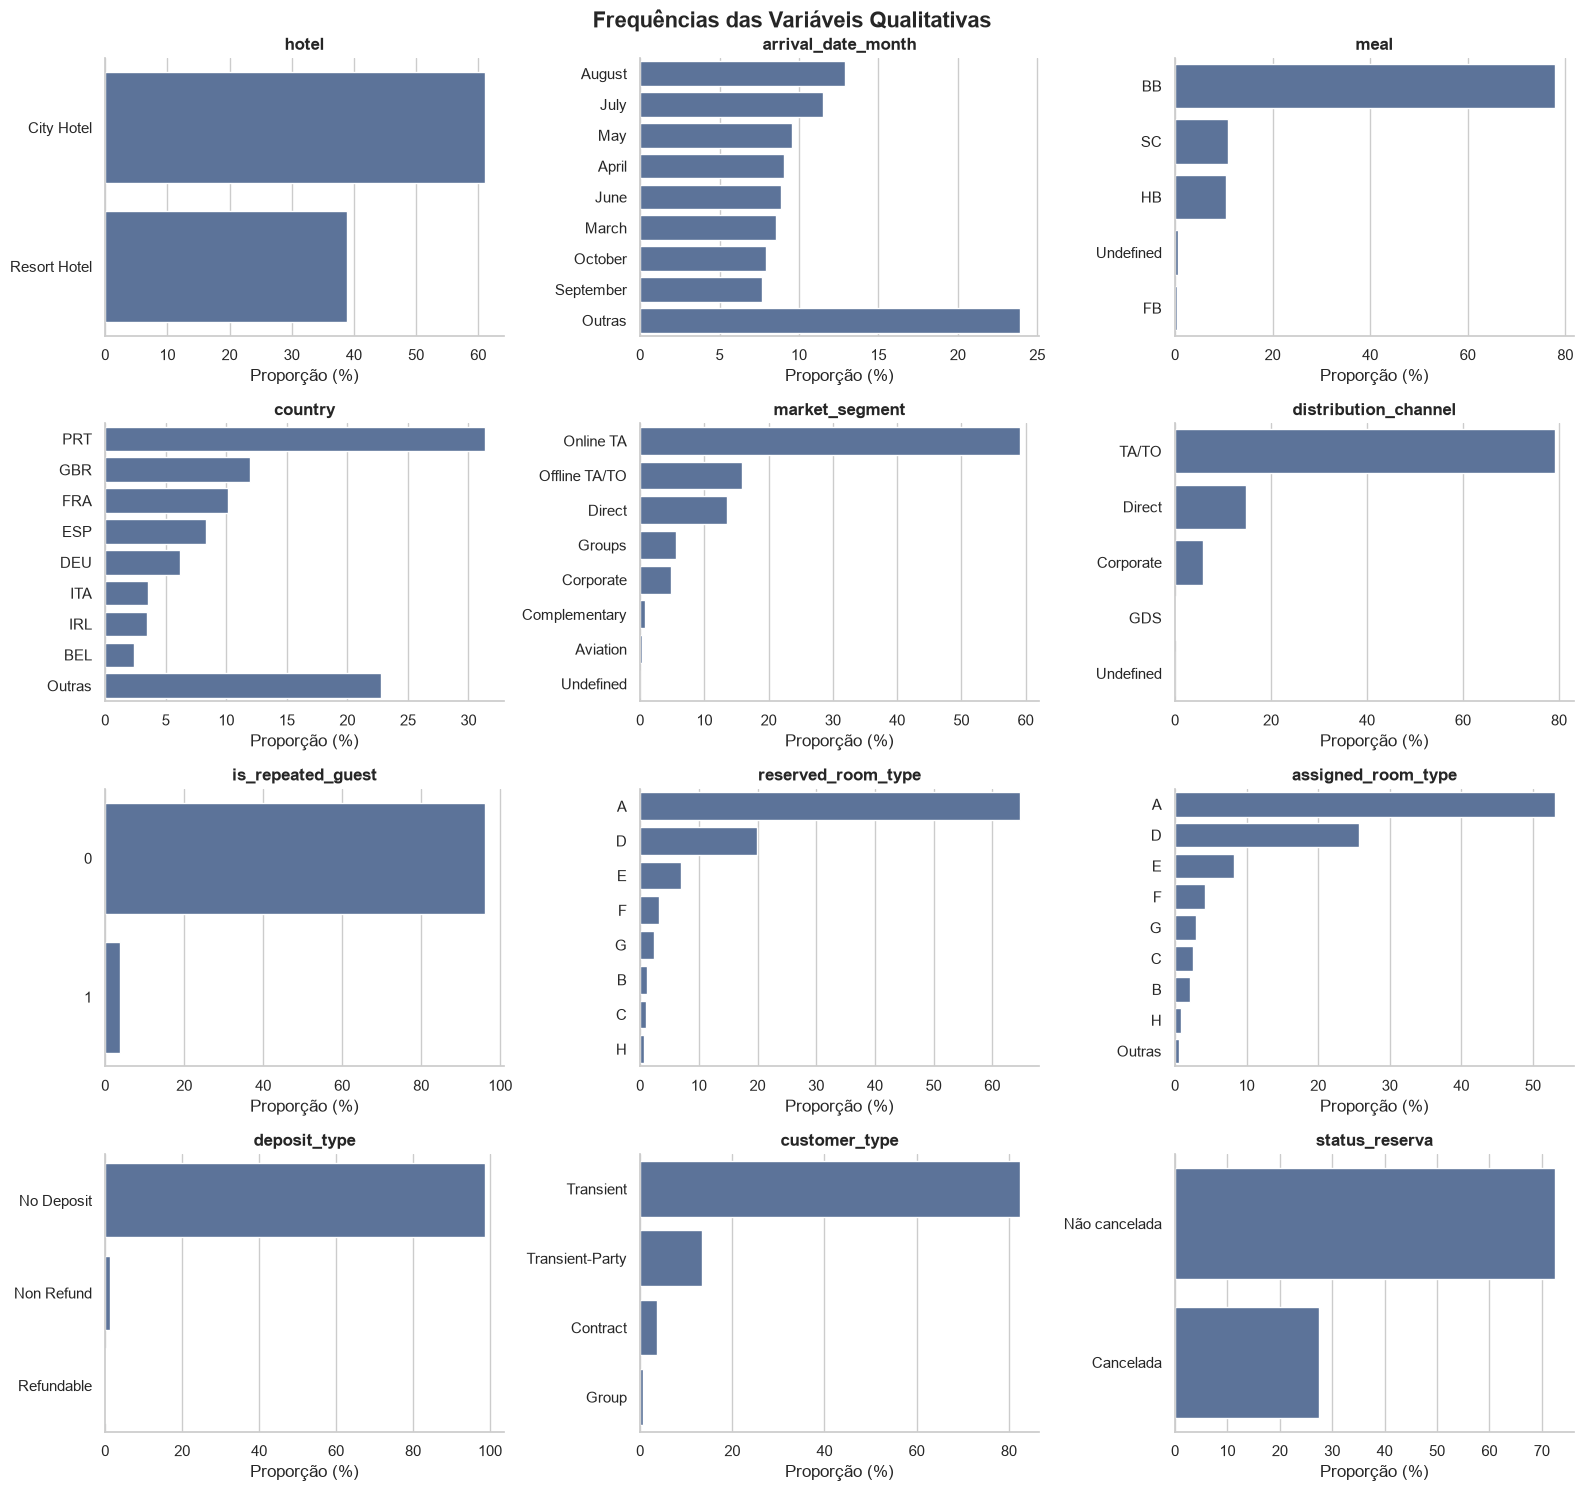

In [29]:
vars_graficos = [
    col for col in VARS_QUALI
    if col not in ["agent", "company"]
]

n_colunas = 3
n_linhas = (len(vars_graficos) + n_colunas - 1) // n_colunas

fig, axes = plt.subplots(
    n_linhas, n_colunas,
    figsize=(16, 3.8 * n_linhas)
)
axes = axes.ravel()

for i, col in enumerate(vars_graficos):
    freq = df[col].value_counts(normalize=True).head(8)
    restante = 1 - freq.sum()

    if restante > 0.001:
        freq.loc["Outras"] = restante

    sns.barplot(
        x=freq.values * 100,
        y=freq.index.astype(str),
        color="#5271A3",
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight="bold")
    axes[i].set_xlabel("Proporção (%)")
    axes[i].set_ylabel("")
    sns.despine(ax=axes[i])

for ax in axes[len(vars_graficos):]:
    ax.axis("off")

fig.suptitle(
    "Frequências das Variáveis Qualitativas",
    fontsize=16,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


**Para discutir:** categorias dominantes, como determinado país, canal de distribuição ou tipo de depósito, podem tornar comparações com categorias raras pouco confiáveis. Nesses casos, vale observar também o número absoluto de reservas por grupo.




#### Desbalanceamento entre categorias

A razão compara a categoria mais frequente com a menos frequente; a entropia normalizada se aproxima de 1 quando as categorias estão distribuídas de forma mais equilibrada.


In [30]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    n_classes = len(contagens)

    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": (
            contagens.max() / contagens.min()
            if n_classes > 1 else np.nan
        ),
        "entropia_normalizada": (
            entropy(contagens / contagens.sum(), base=2)
            / np.log2(n_classes)
            if n_classes > 1 else np.nan
        )
    })

vars_para_checar = list(dict.fromkeys(
    vars_graficos + ["status_reserva"]
))

(
    pd.DataFrame({
        col: metrica_desbalanceamento(df[col])
        for col in vars_para_checar
    })
    .T
    .round(3)
)

,n_classes,razao_desbalanceamento,entropia_normalizada
hotel,2.0,1.569,0.964
arrival_date_month,12.0,2.400,0.986
meal,5.0,188.628,0.449
country,178.0,27355.000,0.518
market_segment,8.0,25776.500,0.594
distribution_channel,5.0,13805.600,0.402
is_repeated_guest,2.0,24.938,0.236
reserved_room_type,9.0,9405.833,0.510
assigned_room_type,11.0,46283.000,0.572
deposit_type,3.0,804.523,0.067



**Para discutir:** `status_reserva` apresenta desbalanceamento entre reservas canceladas e não canceladas? Isso não impede a análise, mas um eventual modelo preditivo deve ser avaliado com métricas adequadas às duas classes. Para variáveis com muitas categorias raras, como `country`, a razão de desbalanceamento pode ficar muito alta apenas porque alguma categoria aparece poucas vezes; interprete-a junto às frequências e à entropia.

### Análise bivariada

Agora avaliamos relações entre as variáveis quantitativas e observamos se reservas canceladas e não canceladas ocupam regiões diferentes dos gráficos.




#### Quantitativa × quantitativa — correlação

Pearson mede associação linear; Spearman e Kendall medem associação monotônica. A normalidade **não é exigida para calcular Pearson**, mas a forte assimetria e os outliers podem afetá-lo. Para comparar os três métodos de forma justa e manter o Colab ágil, usamos a mesma amostra reproduzível de 5.000 reservas.



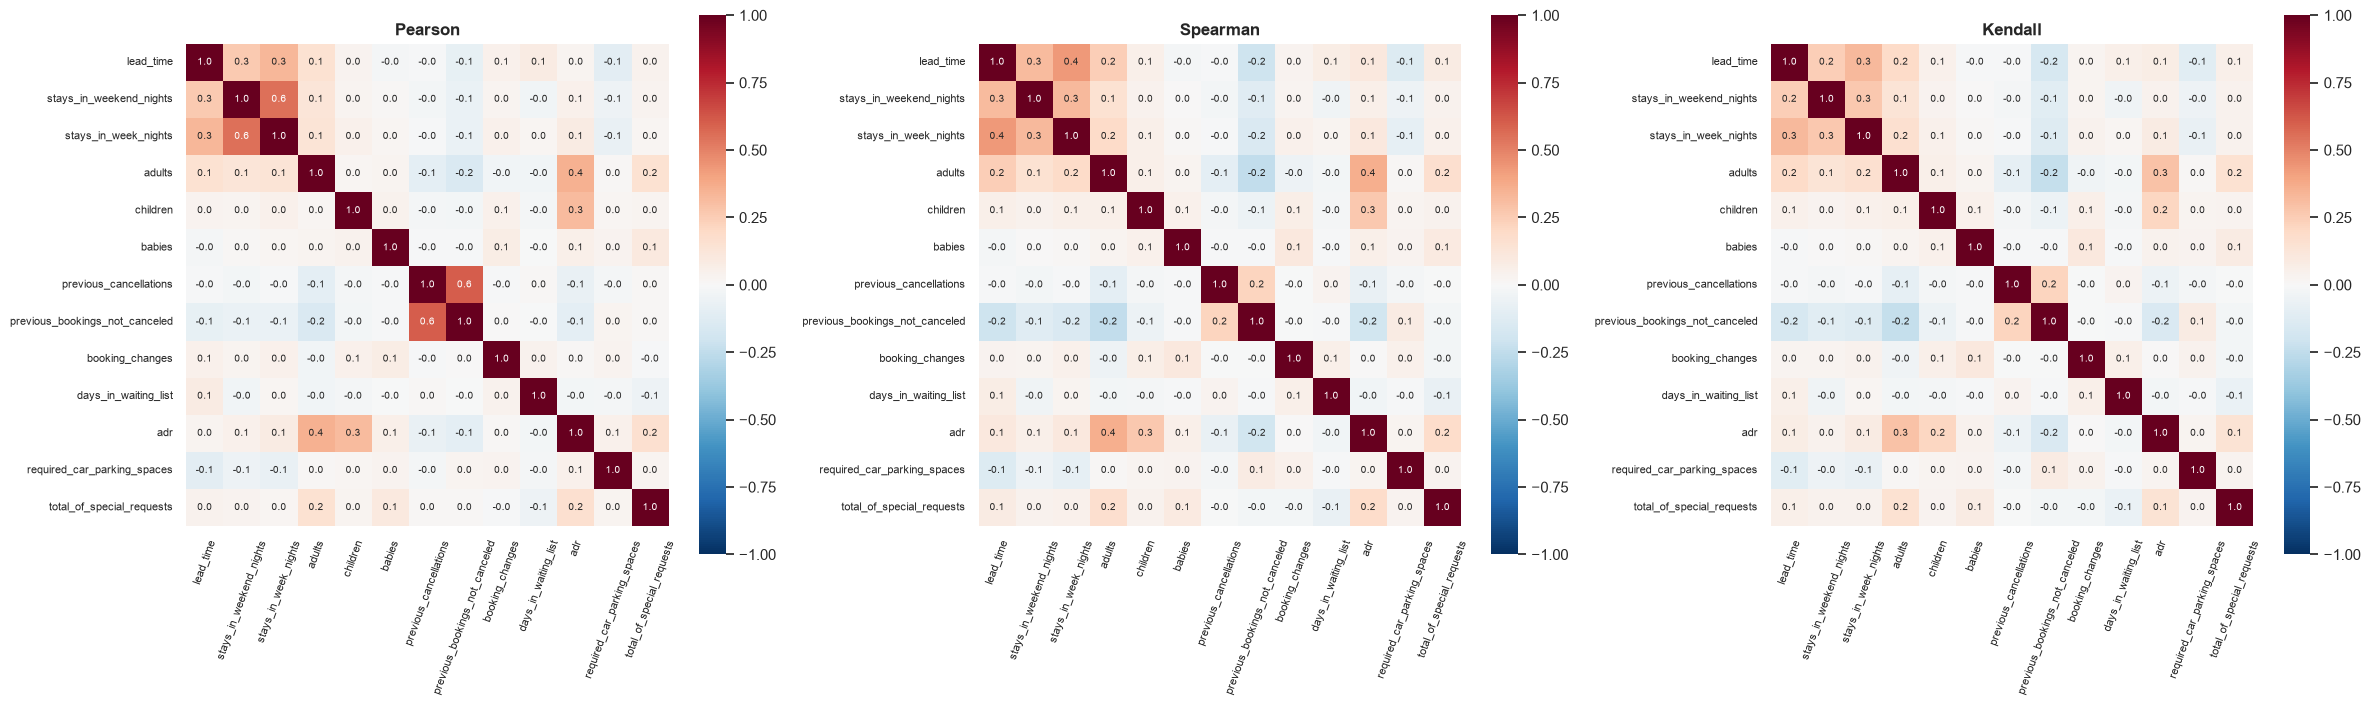

In [31]:
dados_corr = df[VARS_QUANT].dropna().sample(
    n=min(5000, df[VARS_QUANT].dropna().shape[0]),
    random_state=42
)

correlacoes = {
    "Pearson": dados_corr.corr(method="pearson"),
    "Spearman": dados_corr.corr(method="spearman"),
    "Kendall": dados_corr.corr(method="kendall")
}

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (metodo, matriz) in zip(axes, correlacoes.items()):
    sns.heatmap(
        matriz,
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt=".1f",
        annot_kws={"size": 7},
        square=True,
        ax=ax
    )
    ax.set_title(metodo, fontweight="bold")
    ax.tick_params(axis="x", rotation=70, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

Como a matriz é simétrica, podemos destacar somente uma metade da correlação de Spearman:

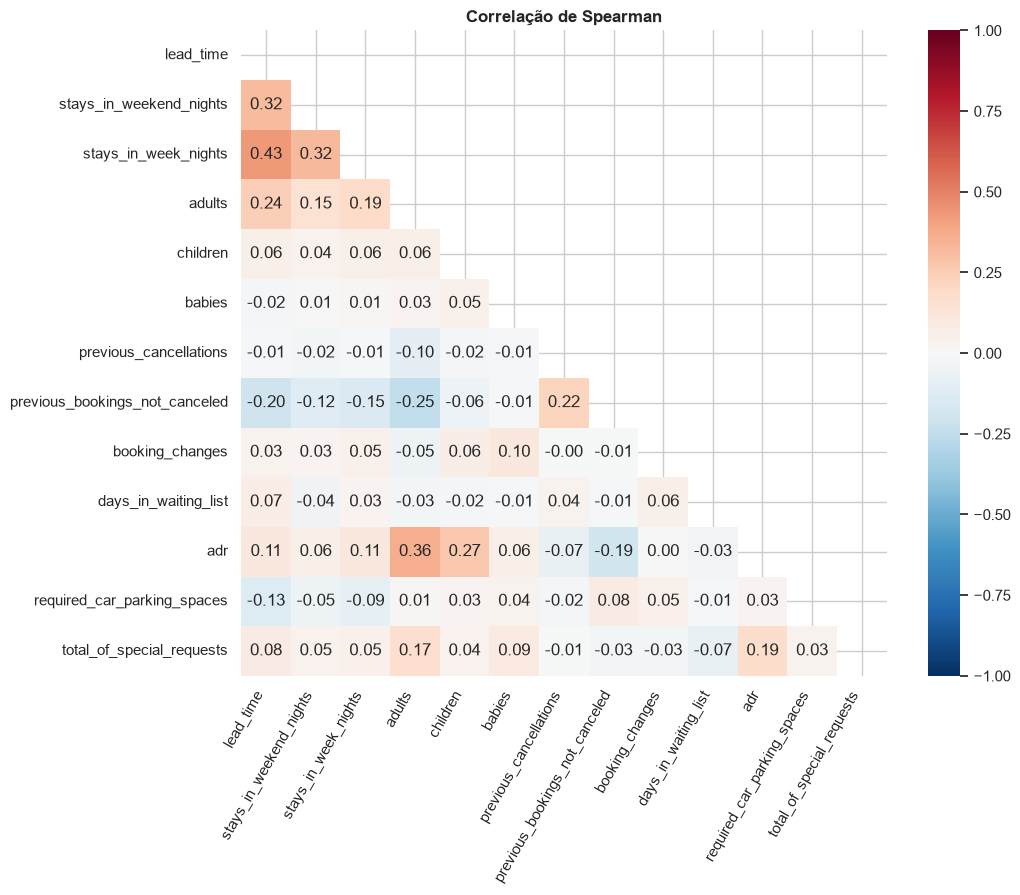

In [32]:
corr_spearman = correlacoes["Spearman"]
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_spearman,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlação de Spearman", fontweight="bold")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


**Para discutir:** Pearson e Spearman divergem em algum par? A diferença pode decorrer de uma relação não linear, de outliers ou de muitos valores repetidos — não comprova, sozinha, que a relação seja não linear. Observe também se há correlações esperadas pelo negócio, como entre noites de semana e noites de fim de semana.



#### Dispersão entre duas variáveis quantitativas

Escolhemos `lead_time` × `adr` por uma hipótese de negócio: a antecedência da reserva pode estar associada à tarifa diária. As cores mostram o status da reserva. Para evitar sobreposição de milhares de pontos, o gráfico usa uma amostra e um recorte **apenas visual** dos valores extremos.


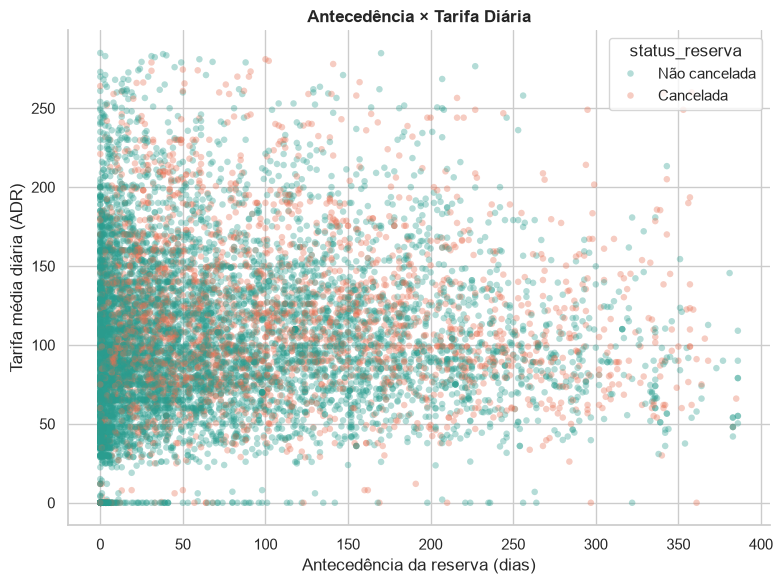

In [33]:
lim_lead = df["lead_time"].quantile(0.995)
lim_adr = df["adr"].quantile(0.995)

dados_scatter = df.loc[
    (df["lead_time"] <= lim_lead)
    & (df["adr"] <= lim_adr),
    ["lead_time", "adr", "status_reserva"]
].dropna()

dados_scatter = dados_scatter.sample(
    n=min(10000, len(dados_scatter)),
    random_state=42
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=dados_scatter,
    x="lead_time",
    y="adr",
    hue="status_reserva",
    hue_order=["Não cancelada", "Cancelada"],
    palette=CORES_STATUS,
    alpha=0.35,
    s=22,
    linewidth=0
)

plt.title("Antecedência × Tarifa Diária", fontweight="bold")
plt.xlabel("Antecedência da reserva (dias)")
plt.ylabel("Tarifa média diária (ADR)")
sns.despine()
plt.tight_layout()
plt.show()


**Para discutir:** há tendência visível entre antecedência e tarifa? As reservas canceladas se concentram em alguma região, ou as duas classes estão misturadas? Mesmo que apareça uma associação, o gráfico não demonstra que a antecedência *cause* uma mudança na tarifa ou no cancelamento.

#### Quantitativa × qualitativa — comparando grupos

Vamos comparar as variáveis quantitativas entre reservas “Não canceladas” e “Canceladas”. Usamos o teste **t de Welch** como contraste e **Mann-Whitney U** como resultado não paramétrico principal.

A rejeição de normalidade no conjunto inteiro não prova, por si só, que cada grupo seja não normal. Além disso, com mais de 119 mil reservas, diferenças pequenas podem gerar p-valores baixos; por isso, observamos também as medianas.


In [34]:
resultados_comparacao = []

for col in VARS_QUANT:
    nao_cancelada = df.loc[
        df["status_reserva"] == "Não cancelada", col
    ].dropna()

    cancelada = df.loc[
        df["status_reserva"] == "Cancelada", col
    ].dropna()

    _, p_t = stats.ttest_ind(
        nao_cancelada, cancelada,
        equal_var=False
    )

    _, p_u = stats.mannwhitneyu(
        nao_cancelada, cancelada,
        alternative="two-sided"
    )

    resultados_comparacao.append({
        "variavel": col,
        "mediana_nao_cancelada": nao_cancelada.median(),
        "mediana_cancelada": cancelada.median(),
        "p_valor_welch": p_t,
        "p_valor_mannwhitney": p_u,
        "concordam": (p_t < 0.05) == (p_u < 0.05)
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

,mediana_nao_cancelada,mediana_cancelada,p_valor_welch,p_valor_mannwhitney,concordam
variavel,,,,,
lead_time,38.00,80.0,0.000000e+00,0.000000e+00,True
stays_in_weekend_nights,1.00,1.0,1.126941e-68,4.965935e-70,True
stays_in_week_nights,2.00,2.0,2.308870e-126,8.693190e-176,True
adults,2.00,2.0,3.165327e-82,2.537398e-153,True
children,0.00,0.0,2.943820e-71,6.165086e-73,True
babies,0.00,0.0,7.846977e-13,3.034107e-10,True
previous_cancellations,0.00,0.0,8.788765e-34,5.466122e-306,True
previous_bookings_not_canceled,0.00,0.0,3.567386e-102,1.551854e-205,True
booking_changes,0.00,0.0,1.595457e-209,1.819589e-292,True



**Para discutir:** os testes concordam? Quando divergem, investigue o formato das distribuições e os outliers. Mann-Whitney compara as posições das distribuições; ele **não é simplesmente um teste de diferença entre medianas**. Também não basta um p-valor significativo: verifique se a diferença observada é relevante para o negócio.

*Exemplo com três ou mais grupos — ANOVA × Kruskal-Wallis*

Vamos comparar `adr` entre os segmentos de mercado (`market_segment`).


ANOVA — ADR por segmento: estatística=1922.846, p-valor=0.000e+00
Kruskal-Wallis — ADR por segmento: estatística=14883.007, p-valor=0.000e+00


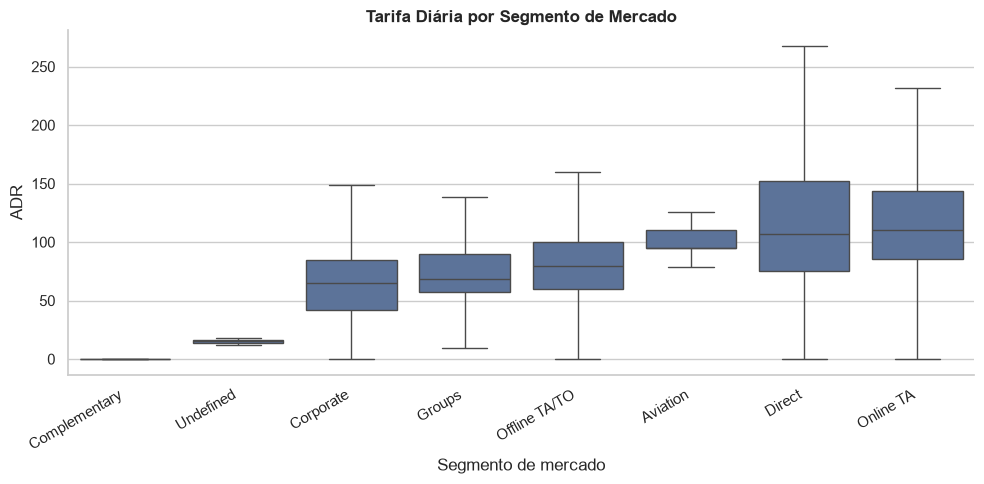

In [35]:
grupos_segmento = [
    grupo["adr"].dropna().values
    for _, grupo in df.groupby("market_segment")
]

stat_anova, p_anova = stats.f_oneway(*grupos_segmento)
stat_kw, p_kw = stats.kruskal(*grupos_segmento)

print(
    f"ANOVA — ADR por segmento: "
    f"estatística={stat_anova:.3f}, p-valor={p_anova:.3e}"
)

print(
    f"Kruskal-Wallis — ADR por segmento: "
    f"estatística={stat_kw:.3f}, p-valor={p_kw:.3e}"
)

ordem = (
    df.groupby("market_segment")["adr"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="market_segment",
    y="adr",
    order=ordem,
    color="#5271A3",
    showfliers=False
)

plt.title("Tarifa Diária por Segmento de Mercado", fontweight="bold")
plt.xlabel("Segmento de mercado")
plt.ylabel("ADR")
plt.xticks(rotation=30, ha="right")
sns.despine()
plt.tight_layout()
plt.show()


**Para discutir:** o Kruskal-Wallis indica diferença entre pelo menos dois segmentos? Se indicar, ele **não identifica quais pares** diferem; isso exigiria uma análise posterior. A ANOVA fica como comparação, enquanto o Kruskal-Wallis é mais adequado como resultado principal diante da forte assimetria de `adr`.

#### Qualitativa × qualitativa — associação com cancelamento

O exemplo `thal` × doença cardíaca cruza **duas variáveis qualitativas**. No dataset de hotéis, vamos cruzar `deposit_type` com `status_reserva` e aplicar o teste Qui-Quadrado.


Qui-Quadrado: p-valor=0.000e+00
Menor frequência esperada: 29.5


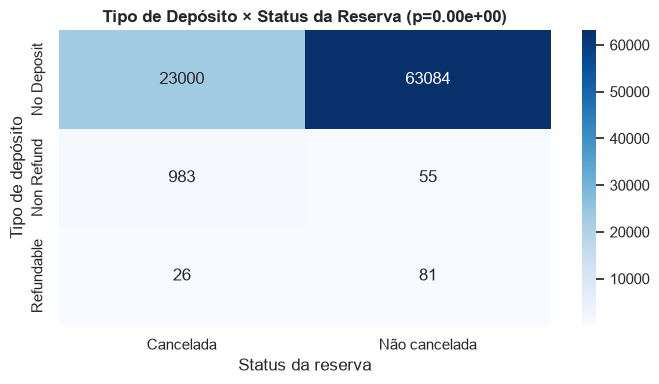

In [36]:
contingencia = pd.crosstab(
    df["deposit_type"],
    df["status_reserva"]
)

chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia)

print(f"Qui-Quadrado: p-valor={p_chi2:.3e}")
print(f"Menor frequência esperada: {esperado.min():.1f}")

plt.figure(figsize=(7, 4))

sns.heatmap(
    contingencia,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    f"Tipo de Depósito × Status da Reserva (p={p_chi2:.2e})",
    fontweight="bold"
)
plt.xlabel("Status da reserva")
plt.ylabel("Tipo de depósito")
plt.tight_layout()
plt.show()


**Para discutir:** se `p < 0,05`, rejeitamos a hipótese de independência: há associação estatística entre o tipo de depósito e o cancelamento. Isso não demonstra que o depósito *causou* o cancelamento. Também devemos conferir as frequências esperadas, sobretudo nas categorias menos comuns.



#### Análise de subgrupos e *fairness*

Este dataset **não contém sexo nem idade dos hóspedes**. Podemos comparar as taxas de cancelamento por `country` (possível indicador de origem geográfica) e `customer_type` (categoria comercial), mas isso **não constitui uma auditoria completa de justiça algorítmica**. Para evitar grupos de países muito pequenos, reunimos os demais em “Outros” e mantemos a origem não informada separada.



grupo_pais: Qui-Quadrado p=0.000e+00
Reservas por grupo:
grupo_pais
DEU               5385
ESP               7244
FRA               8823
GBR              10423
Não informado      447
Outros           27552
PRT              27355
dtype: int64



customer_type: Qui-Quadrado p=7.898e-306
Reservas por grupo:
customer_type
Contract            3135
Group                541
Transient          71862
Transient-Party    11691
dtype: int64


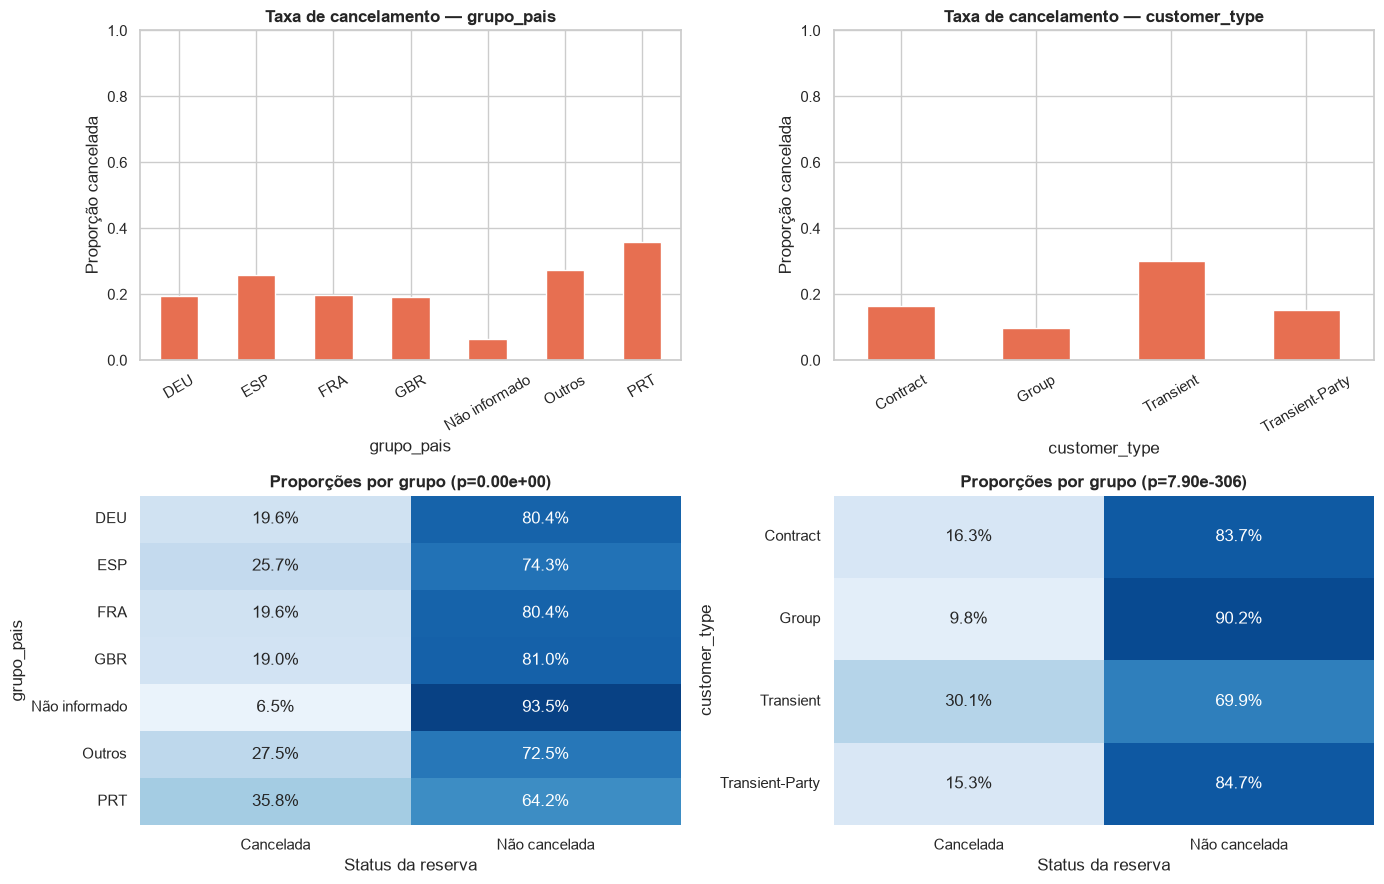

In [37]:
df_analise = df.copy()

paises_top = (
    df_analise["country"]
    .value_counts()
    .drop("Unknown", errors="ignore")
    .head(5)
    .index
)

df_analise["grupo_pais"] = df_analise["country"].where(
    df_analise["country"].isin(paises_top),
    "Outros"
)

df_analise.loc[
    df_analise["country"] == "Unknown",
    "grupo_pais"
] = "Não informado"

atributos = ["grupo_pais", "customer_type"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, atributo in enumerate(atributos):
    tabela = pd.crosstab(
        df_analise[atributo],
        df_analise["status_reserva"]
    )

    proporcoes = tabela.div(tabela.sum(axis=1), axis=0)
    taxa_cancelamento = proporcoes["Cancelada"]

    chi2, p_valor, gl, esperado = stats.chi2_contingency(tabela)

    print(f"\n{atributo}: Qui-Quadrado p={p_valor:.3e}")
    print("Reservas por grupo:")
    print(tabela.sum(axis=1))

    taxa_cancelamento.plot.bar(
        color="#E76F51",
        ax=axes[0, i]
    )
    axes[0, i].set_title(
        f"Taxa de cancelamento — {atributo}",
        fontweight="bold"
    )
    axes[0, i].set_ylabel("Proporção cancelada")
    axes[0, i].set_ylim(0, 1)
    axes[0, i].tick_params(axis="x", rotation=30)

    sns.heatmap(
        proporcoes,
        annot=True,
        fmt=".1%",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        ax=axes[1, i]
    )
    axes[1, i].set_title(
        f"Proporções por grupo (p={p_valor:.2e})",
        fontweight="bold"
    )
    axes[1, i].set_xlabel("Status da reserva")
    axes[1, i].set_ylabel(atributo)

plt.tight_layout()
plt.show()


**Para discutir:** as taxas de cancelamento variam entre os grupos? O Qui-Quadrado pode indicar associação, mas não explica sua causa. Diferenças por país podem refletir canais de venda, políticas comerciais ou composição das reservas; diferenças por `customer_type` são diferenças entre segmentos de negócio, não necessariamente um problema de *fairness*. Antes de tirar conclusões, compare também o **número de reservas** em cada grupo e investigue fatores que possam explicar as disparidades.

### Associação entre subgrupos e cancelamento

O dataset de hotéis não possui `sex` nem `age`. Reaproveitamos `grupo_pais` e `customer_type`, criados na seção anterior. A análise mostra associação entre grupos e cancelamento, mas não explica sua causa.


grupo_pais: p=0.000e+00 | menor frequência esperada=123.0


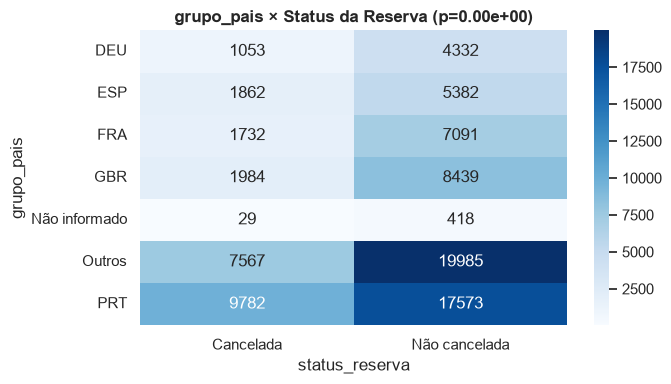

customer_type: p=7.898e-306 | menor frequência esperada=148.9


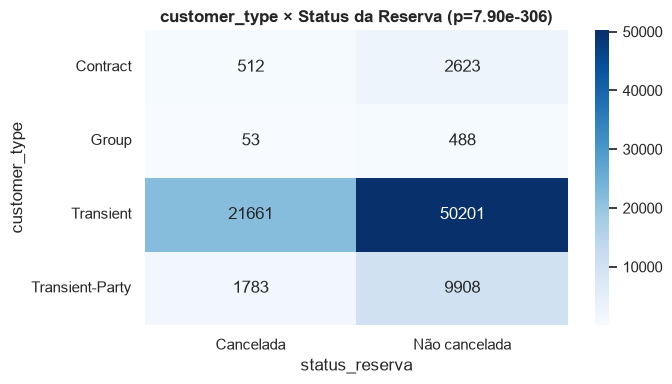

In [38]:
for atributo in ["grupo_pais", "customer_type"]:
    contingencia = pd.crosstab(
        df_analise[atributo],
        df_analise["status_reserva"]
    )

    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    print(
        f"{atributo}: p={p_valor:.3e} | "
        f"menor frequência esperada={esperado.min():.1f}"
    )

    fig, ax = plt.subplots(figsize=(7, 4))
    sns.heatmap(
        contingencia,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
    )
    ax.set_title(
        f"{atributo} × Status da Reserva (p={p_valor:.2e})",
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()


**Para discutir:** o Qui-Quadrado aponta associação? País de origem pode funcionar como indicador geográfico, enquanto `customer_type` é uma classificação comercial — não um atributo protegido. Mesmo uma associação significativa não demonstra viés algorítmico nem causalidade.



#### Outliers bivariados

Vamos observar combinações incomuns de `lead_time` e `adr`. Para manter o gráfico legível, mostramos uma amostra de reservas **mais todos os registros no 1% superior** de pelo menos uma das duas variáveis. Nenhum extremo é eliminado do gráfico.



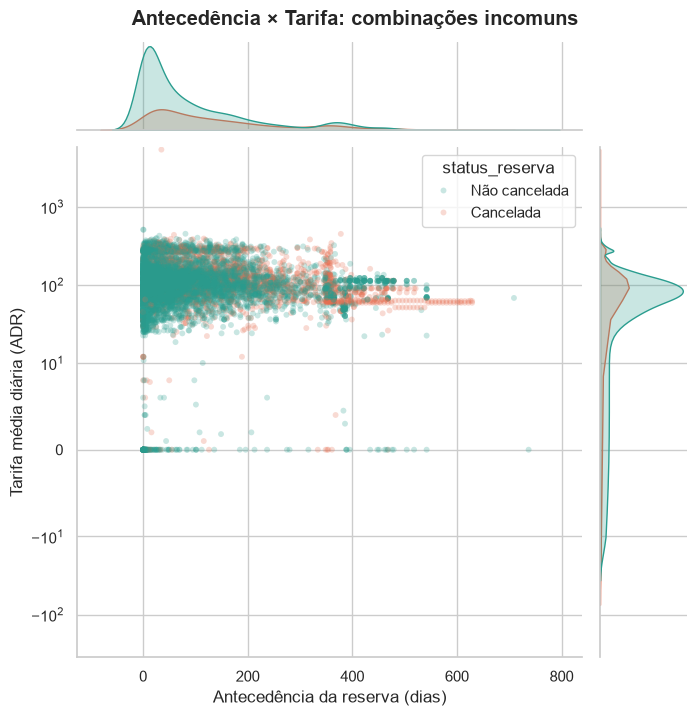

In [39]:
amostra = df.sample(
    n=min(8000, len(df)),
    random_state=42
)

extremos = df.loc[
    (df["lead_time"] > df["lead_time"].quantile(0.99))
    | (df["adr"] > df["adr"].quantile(0.99))
]

indices_plot = amostra.index.union(extremos.index)

dados_joint = df.loc[
    indices_plot,
    ["lead_time", "adr", "status_reserva"]
].dropna()

g = sns.jointplot(
    data=dados_joint,
    x="lead_time",
    y="adr",
    hue="status_reserva",
    hue_order=["Não cancelada", "Cancelada"],
    palette=CORES_STATUS,
    kind="scatter",
    height=7,
    joint_kws={
        "alpha": 0.25,
        "s": 18,
        "linewidth": 0
    }
)

# Escala visual que preserva ADR igual a zero e mostra tarifas extremas
g.ax_joint.set_yscale("symlog", linthresh=10)
g.ax_marg_y.set_yscale("symlog", linthresh=10)

g.ax_joint.set_xlabel("Antecedência da reserva (dias)")
g.ax_joint.set_ylabel("Tarifa média diária (ADR)")
g.figure.suptitle(
    "Antecedência × Tarifa: combinações incomuns",
    y=1.02,
    fontweight="bold"
)
plt.show()


**Para discutir:** há reservas com antecedência e tarifa individualmente comuns, mas cuja *combinação* é rara? O gráfico ajuda a levantar essa hipótese; não constitui, sozinho, um método formal de detecção de outliers bivariados. O `jointplot` reúne a dispersão e as distribuições marginais. [Documentação do Seaborn](https://seaborn.pydata.org/generated/seaborn.jointplot.html)



#### Análise Multivariada

##### Matriz de Correlação

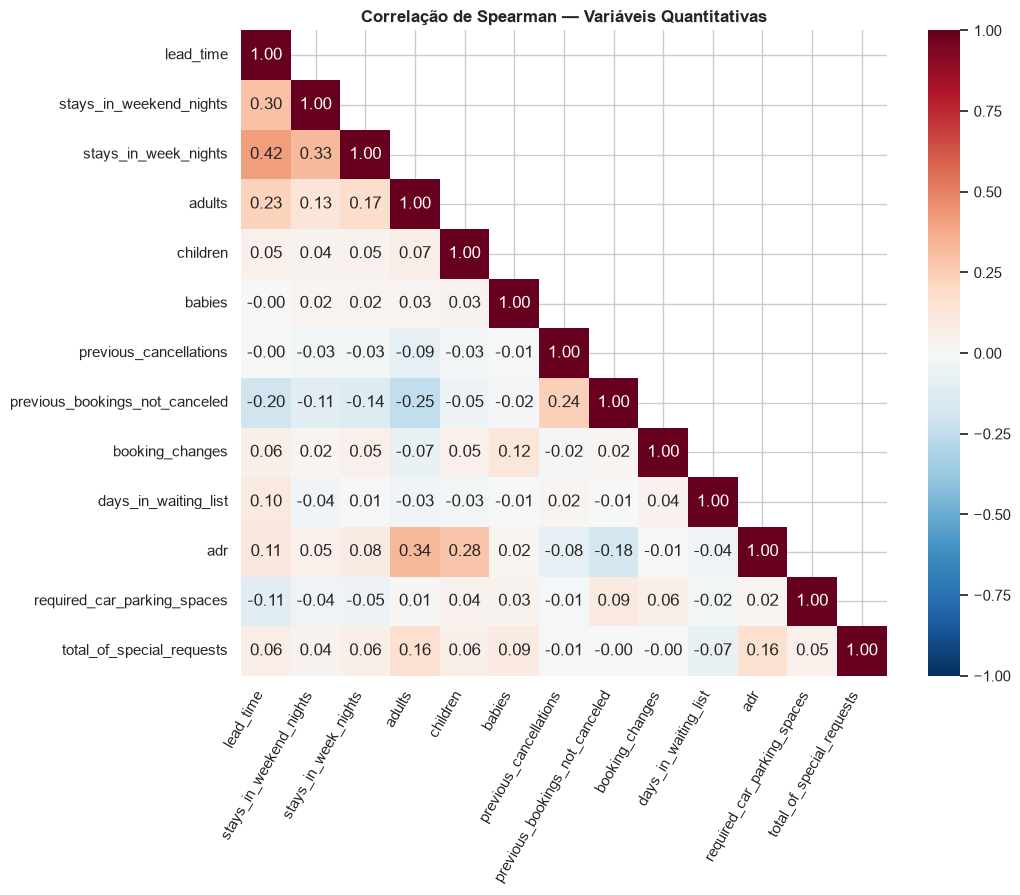

In [40]:
corr_spearman_completa = df[VARS_QUANT].corr(
    method="spearman"
)

mask = np.triu(
    np.ones_like(corr_spearman_completa, dtype=bool),
    k=1
)

plt.figure(figsize=(11, 9))

sns.heatmap(
    corr_spearman_completa,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title(
    "Correlação de Spearman — Variáveis Quantitativas",
    fontweight="bold"
)
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


**Como interpretar:** valores próximos de zero indicam associação monotônica fraca; próximos de −1 ou 1, associação mais forte. Os cortes 0,3 e 0,7 são apenas referências, não regras universais. Verifique especialmente se variáveis ligadas à duração da estadia apresentam redundância.



##### Correlograma


Com 13 variáveis e mais de 119 mil reservas, um `PairGrid` completo ficaria pesado e pouco legível. Selecionamos cinco variáveis e 2.500 registros para a visualização; na metade superior, o círculo representa a correlação de **Spearman**, coerente com a matriz acima.


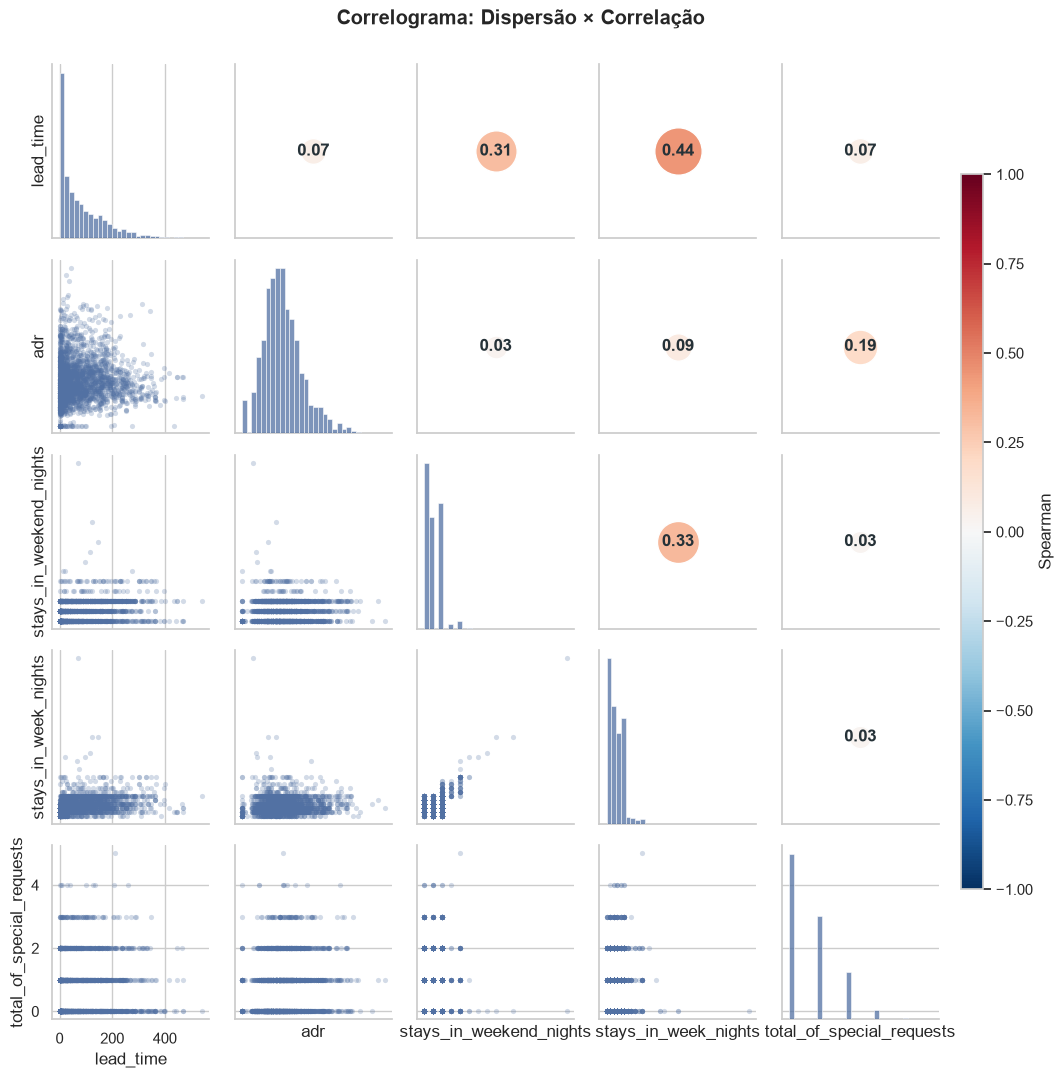

In [41]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

vars_correlograma = [
    "lead_time",
    "adr",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "total_of_special_requests"
]

dados_grid = df[vars_correlograma].dropna().sample(
    n=min(2500, len(df[vars_correlograma].dropna())),
    random_state=42
)

def circulo_correlacao(x, y, **kwargs):
    r, _ = stats.spearmanr(x, y)
    ax = plt.gca()

    ax.scatter(
        0.5, 0.5,
        s=200 + abs(r) * 2200,
        c=[r],
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        transform=ax.transAxes,
        edgecolor="white"
    )

    ax.text(
        0.5, 0.5,
        f"{r:.2f}",
        transform=ax.transAxes,
        ha="center",
        va="center",
        color="white" if abs(r) > 0.5 else "#263238",
        fontweight="bold"
    )

    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(dados_grid, diag_sharey=False, height=2.2)

g.map_lower(
    sns.scatterplot,
    color="#5271A3",
    alpha=0.25,
    s=14,
    linewidth=0
)

g.map_diag(
    sns.histplot,
    color="#5271A3",
    bins=30
)

g.map_upper(circulo_correlacao)

sm = ScalarMappable(
    norm=Normalize(-1, 1),
    cmap="RdBu_r"
)
sm.set_array([])

g.figure.subplots_adjust(top=0.93, right=0.88)
cax = g.figure.add_axes([0.90, 0.18, 0.02, 0.65])
g.figure.colorbar(sm, cax=cax, label="Spearman")

g.figure.suptitle(
    "Correlograma: Dispersão × Correlação",
    fontweight="bold"
)
plt.show()


**Para discutir:** alguma dupla forma um padrão claro na dispersão e também apresenta um círculo grande? Isso pode sugerir associação ou redundância, mas não implica causalidade. O `PairGrid` permite combinar visualizações distintas na diagonal e nos dois triângulos. [Documentação do Seaborn](https://seaborn.pydata.org/generated/seaborn.PairGrid.html)

## Exportação dos datasets (Aula 21)

Salva o dataset original em `data/raw/` e o tratado (estado final do `df`) em `data/clean/`, que é o arquivo lido pelo `app.py`.

In [42]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [43]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (relido do CSV baixado pelo kagglehub, sem nenhum tratamento)
df_raw = pd.read_csv(arquivo_csv)
df_raw.to_csv(PASTA_RAW / "hotel_bookings.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'hotel_bookings.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\hotel_bookings.csv — 119390 linhas x 32 colunas


In [44]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 87229 linhas x 33 colunas
Linhas removidas no tratamento: 32161
